# Load, Process, Etc.

Imports and Dependencies

In [5]:
# === Install dependencies ===
!pip install optuna imbalanced-learn scikit-learn matplotlib seaborn

# === Imports ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE
import optuna
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

Load Data

In [6]:
# === Load Data ===
# train_df = pd.read_csv('/content/drive/MyDrive/features_train.csv')
# val_df = pd.read_csv('/content/drive/MyDrive/features_val.csv')
# test_df = pd.read_csv('/content/drive/MyDrive/features_test.csv')
full_df = pd.read_csv('/content/drive/MyDrive/features.csv')

# 70/15/15 split
train_df, temp_df = train_test_split(full_df, test_size=0.3, stratify=full_df['emotion'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['emotion'], random_state=42)

Download the datasets or checkout the face code
  * Full Features: https://drive.google.com/file/d/16Vzmb3PdcFWskcPfI9xlO0qp8ZWe3k-b/view?usp=sharing
  * Train Split: https://drive.google.com/file/d/1Rp-JDZyl5gHuD-G3YUuGe6NPeKyaa2q4/view?usp=sharing
  * Validation Split: https://drive.google.com/file/d/1lHBNYt8GrcpXWnq6-ZO9cEl8amR0gm_L/view?usp=sharing
  * Test Split: https://drive.google.com/file/d/1nWYBatHU6pwqH58MKYbR8q8mn2UioRY9/view?usp=sharing


* Landmark Code: https://colab.research.google.com/drive/1CP99rtwBr_FoWFtjo5iQnltFPDwqUb7n?usp=sharing
* Features Code: https://colab.research.google.com/drive/1-VIYaIPwBZfZKeZQ0Fh0YqIuH4Z0vMav?usp=sharing

Preprocessing

In [7]:
# === Preprocessing ===
def clean_tuple_strings(df):
    for column in df.columns:
        if df[column].dtype == 'object':
            df[column] = df[column].apply(lambda x: float(str(x).strip('()').split(',')[0]))
    return df

experiment_results = {}

# Raw Data
X_train_raw = clean_tuple_strings(train_df.drop(columns=["image_name", "emotion"]))
X_val_raw = clean_tuple_strings(val_df.drop(columns=["image_name", "emotion"]))
X_test_raw = clean_tuple_strings(test_df.drop(columns=["image_name", "emotion"]))
y_train_raw = train_df["emotion"]
y_val_raw = val_df["emotion"]
y_test_raw = test_df["emotion"]

# Label Encoded
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)
y_val = label_encoder.transform(y_val_raw)
y_test = label_encoder.transform(y_test_raw)

# Scaling and SMOTE
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# Feature Selection
selector_all = SelectKBest(score_func=f_classif, k='all')
selector_top10 = SelectKBest(score_func=f_classif, k=15)
X_train_all = selector_all.fit_transform(X_train_smote, y_train_smote)
X_val_all = selector_all.transform(X_val_scaled)
X_test_all = selector_all.transform(X_test_scaled)
X_train_top10 = selector_top10.fit_transform(X_train_smote, y_train_smote)
X_val_top10 = selector_top10.transform(X_val_scaled)
X_test_top10 = selector_top10.transform(X_test_scaled)

Helper Functions

In [8]:
# === Helper Functions ===
def full_evaluation(model, X_train, y_train, X_val, y_val, X_test, y_test, title):
    results = {}

    for X, y, name in [(X_train, y_train, 'Train'), (X_val, y_val, 'Validation'), (X_test, y_test, 'Test')]:
        y_pred = model.predict(X)
        f1 = f1_score(y, y_pred, average='macro')
        results[name] = f1


        print(f"\n--- {name} Set Evaluation: {title} ---")
        print(f"F1: {f1:.4f}")
        print(classification_report(y, y_pred, target_names=label_encoder.classes_))
        cm = confusion_matrix(y, y_pred)
        plt.figure(figsize=(8,6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
        sns.color_palette("pastel")
        plt.title(f"Confusion Matrix ({name}) - {title}")
        plt.show()

    # Save results
    experiment_results[title] = results

    return results['Train'], results['Validation'], results['Test']



class CustomMLP(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim, dropout_p):
        super(CustomMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)

def train_mlp(X_train, y_train, X_val, y_val, input_dim, num_classes, hidden_dim=19, dropout_p=0.3, lr=0.0068, weight_decay=0.0222, batch_size=16, epochs=1000):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = CustomMLP(input_dim, num_classes, hidden_dim, dropout_p).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # Convert inputs to pure numpy arrays to avoid DataFrame issues
    X_train_tensor = torch.tensor(np.array(X_train), dtype=torch.float32)
    y_train_tensor = torch.tensor(np.array(y_train), dtype=torch.long)
    train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=batch_size, shuffle=True)

    X_val_tensor = torch.tensor(np.array(X_val), dtype=torch.float32)
    y_val_tensor = torch.tensor(np.array(y_val), dtype=torch.long)

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            optimizer.step()
        if (epoch + 1) % 100 == 0:
            model.eval()
            with torch.no_grad():
                val_preds = model(X_val_tensor.to(device)).argmax(dim=1)
                acc = (val_preds.cpu() == y_val_tensor).float().mean().item()
                print(f"Epoch {epoch+1}: Validation Acc: {acc:.4f}")
    return model



def evaluate_mlp(model, X, y, title):
    model.eval()
    device = next(model.parameters()).device
    X_tensor = torch.tensor(np.array(X), dtype=torch.float32).to(device)
    preds = model(X_tensor).argmax(dim=1).cpu().numpy()

    f1 = f1_score(y, preds, average='macro')
    print(f"\n--- {title} ---")
    print(f"F1 Score: {f1:.4f}")
    print(classification_report(y, preds, target_names=label_encoder.classes_))
    cm = confusion_matrix(y, preds)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f"Confusion Matrix - {title}")
    plt.show()

    if 'Train' in title:
        split = 'Train'
    elif 'Validation' in title:
        split = 'Validation'
    else:
        split = 'Test'

    experiment_name = title.replace(f" ({split})", "")
    if experiment_name not in experiment_results:
        experiment_results[experiment_name] = {}

    experiment_results[experiment_name][split] = f1



# === # === # === Optuna Tuning for MLP (PyTorch) ===
def objective(trial):
    hidden_dim = trial.suggest_int('hidden_dim', 16, 64)
    dropout_p = trial.suggest_float('dropout_p', 0.2, 0.5)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

    model = train_mlp(
        X_train_all, y_train_smote, X_val_all, y_val,
        input_dim=X_train_all.shape[1],
        num_classes=len(label_encoder.classes_),
        hidden_dim=hidden_dim,
        dropout_p=dropout_p,
        lr=lr,
        weight_decay=weight_decay,
        batch_size=batch_size,
        epochs=100
    )

    device = next(model.parameters()).device
    X_val_tensor = torch.tensor(np.array(X_val_all), dtype=torch.float32).to(device)
    y_val_tensor = torch.tensor(np.array(y_val), dtype=torch.long).to(device)
    model.eval()
    with torch.no_grad():
        preds = model(X_val_tensor).argmax(dim=1)
        acc = (preds.cpu() == y_val_tensor.cpu()).float().mean().item()
    return 1.0 - acc

# Raw Data Experiments

In [9]:
# === SECTION: RAW DATA ===
print("\n===== RAW DATA =====")


===== RAW DATA =====


Decision Tree


--- Decision Tree (Raw Data) ---

--- Train Set Evaluation: Decision Tree - Raw Data ---
F1: 1.0000
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00        94
    contempt       1.00      1.00      1.00        38
     disgust       1.00      1.00      1.00       124
        fear       1.00      1.00      1.00        52
       happy       1.00      1.00      1.00       145
     sadness       1.00      1.00      1.00        59
    surprise       1.00      1.00      1.00       174

    accuracy                           1.00       686
   macro avg       1.00      1.00      1.00       686
weighted avg       1.00      1.00      1.00       686



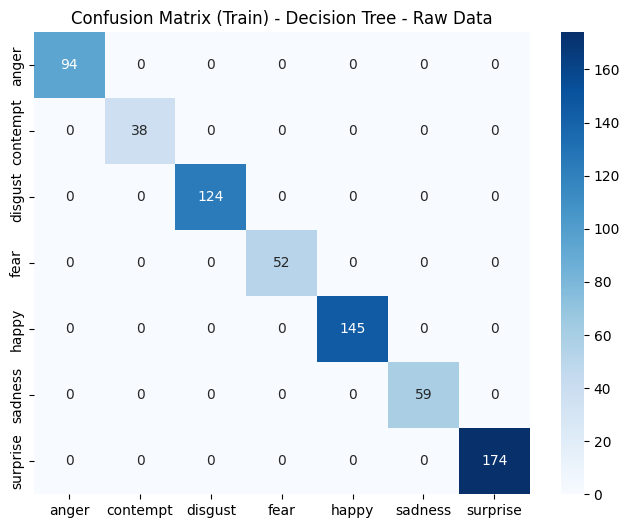


--- Validation Set Evaluation: Decision Tree - Raw Data ---
F1: 0.8144
              precision    recall  f1-score   support

       anger       0.89      0.85      0.87        20
    contempt       0.75      0.75      0.75         8
     disgust       0.82      0.88      0.85        26
        fear       0.70      0.58      0.64        12
       happy       1.00      0.97      0.98        31
     sadness       0.56      0.69      0.62        13
    surprise       1.00      0.97      0.99        37

    accuracy                           0.87       147
   macro avg       0.82      0.81      0.81       147
weighted avg       0.88      0.87      0.87       147



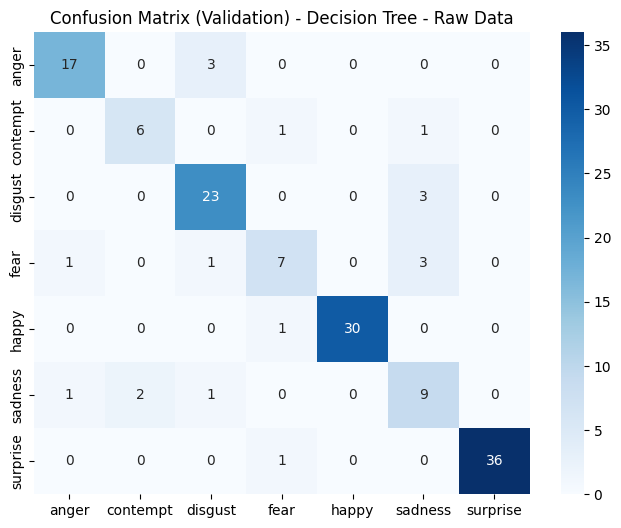


--- Test Set Evaluation: Decision Tree - Raw Data ---
F1: 0.8069
              precision    recall  f1-score   support

       anger       0.58      0.52      0.55        21
    contempt       0.73      1.00      0.84         8
     disgust       0.80      0.74      0.77        27
        fear       1.00      0.64      0.78        11
       happy       0.94      1.00      0.97        31
     sadness       0.67      0.83      0.74        12
    surprise       1.00      1.00      1.00        38

    accuracy                           0.84       148
   macro avg       0.82      0.82      0.81       148
weighted avg       0.85      0.84      0.84       148



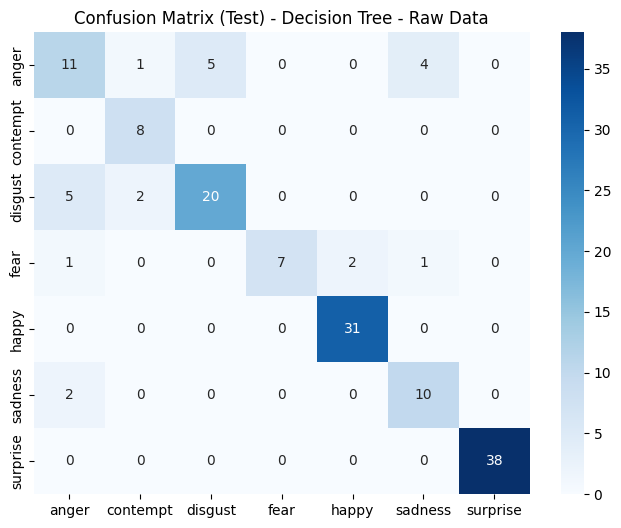

(1.0, 0.8143725632032623, 0.8069435072724547)

In [10]:
# Decision Tree
print("\n--- Decision Tree (Raw Data) ---")
dt_raw = DecisionTreeClassifier(random_state=42)
dt_raw.fit(X_train_raw, y_train)
full_evaluation(dt_raw, X_train_raw, y_train, X_val_raw, y_val, X_test_raw, y_test, "Decision Tree - Raw Data")

Support Vector Machine


--- SVM (Raw Data) ---

--- Train Set Evaluation: SVM - Raw Data ---
F1: 0.4664
              precision    recall  f1-score   support

       anger       0.35      0.39      0.37        94
    contempt       0.23      0.42      0.29        38
     disgust       0.45      0.36      0.40       124
        fear       0.29      0.42      0.34        52
       happy       0.84      0.56      0.67       145
     sadness       0.25      0.39      0.30        59
    surprise       0.99      0.80      0.89       174

    accuracy                           0.53       686
   macro avg       0.48      0.48      0.47       686
weighted avg       0.61      0.53      0.56       686



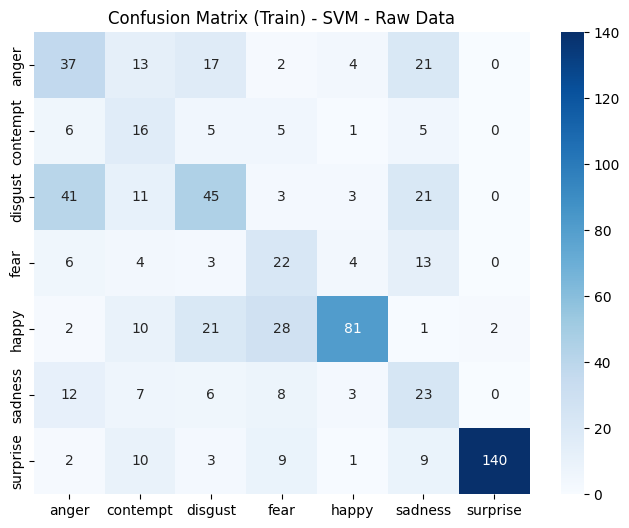


--- Validation Set Evaluation: SVM - Raw Data ---
F1: 0.3934
              precision    recall  f1-score   support

       anger       0.23      0.25      0.24        20
    contempt       0.27      0.50      0.35         8
     disgust       0.37      0.38      0.38        26
        fear       0.12      0.17      0.14        12
       happy       0.80      0.52      0.63        31
     sadness       0.12      0.15      0.14        13
    surprise       0.97      0.81      0.88        37

    accuracy                           0.47       147
   macro avg       0.41      0.40      0.39       147
weighted avg       0.54      0.47      0.50       147



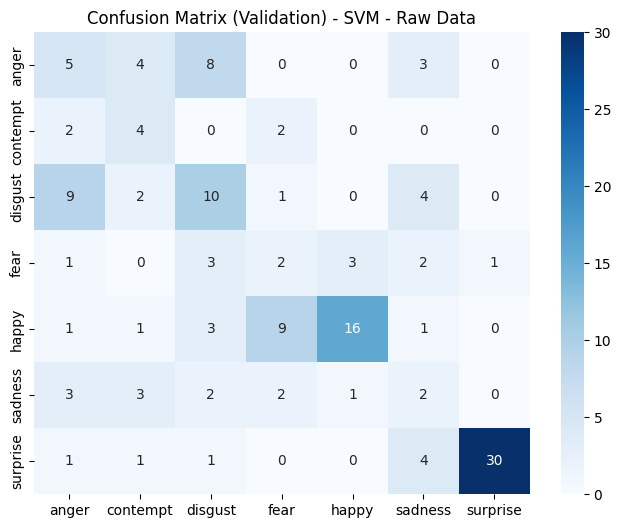


--- Test Set Evaluation: SVM - Raw Data ---
F1: 0.4162
              precision    recall  f1-score   support

       anger       0.36      0.48      0.41        21
    contempt       0.00      0.00      0.00         8
     disgust       0.36      0.33      0.35        27
        fear       0.27      0.27      0.27        11
       happy       0.88      0.71      0.79        31
     sadness       0.18      0.33      0.24        12
    surprise       1.00      0.76      0.87        38

    accuracy                           0.52       148
   macro avg       0.44      0.41      0.42       148
weighted avg       0.59      0.52      0.55       148



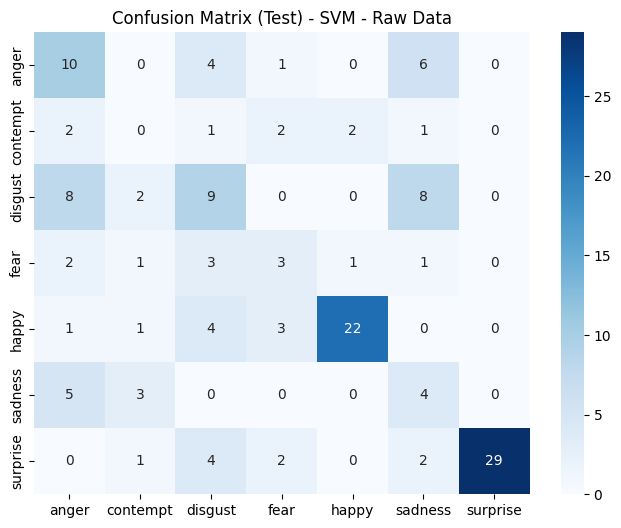

(0.46636828331038327, 0.39341027350376095, 0.4162463470485186)

In [11]:
# SVM
print("\n--- SVM (Raw Data) ---")
svm_raw = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_raw.fit(X_train_raw, y_train)
full_evaluation(svm_raw, X_train_raw, y_train, X_val_raw, y_val, X_test_raw, y_test, "SVM - Raw Data")

Multilayer Perceptron

--- MLP (Raw Data) ---
Epoch 100: Validation Acc: 0.6190
Epoch 200: Validation Acc: 0.6122
Epoch 300: Validation Acc: 0.6122
Epoch 400: Validation Acc: 0.6122
Epoch 500: Validation Acc: 0.6190
Epoch 600: Validation Acc: 0.6122
Epoch 700: Validation Acc: 0.6122
Epoch 800: Validation Acc: 0.6395
Epoch 900: Validation Acc: 0.6190
Epoch 1000: Validation Acc: 0.6190

--- MLP - Raw Data (Train) ---
F1 Score: 0.3298
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        94
    contempt       0.00      0.00      0.00        38
     disgust       0.34      0.94      0.50       124
        fear       0.00      0.00      0.00        52
       happy       0.76      0.93      0.84       145
     sadness       0.00      0.00      0.00        59
    surprise       0.98      0.96      0.97       174

    accuracy                           0.61       686
   macro avg       0.30      0.40      0.33       686
weighted avg       0.47      0.61      0.51  

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


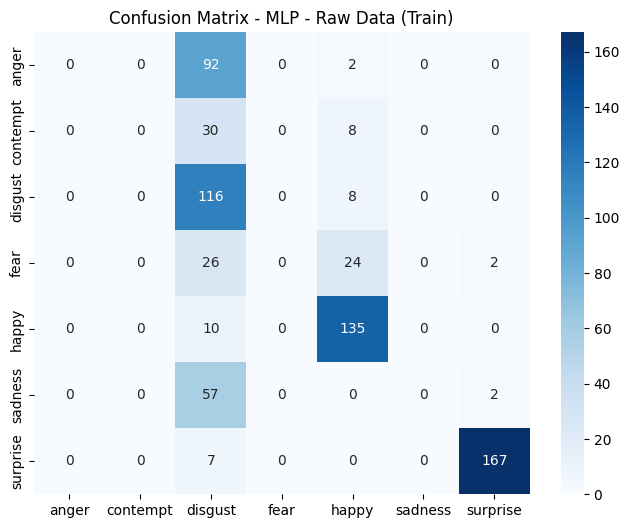


--- MLP - Raw Data (Validation) ---
F1 Score: 0.3327
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        20
    contempt       0.00      0.00      0.00         8
     disgust       0.36      0.96      0.53        26
        fear       0.00      0.00      0.00        12
       happy       0.74      0.94      0.83        31
     sadness       0.00      0.00      0.00        13
    surprise       0.95      1.00      0.97        37

    accuracy                           0.62       147
   macro avg       0.29      0.41      0.33       147
weighted avg       0.46      0.62      0.51       147



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


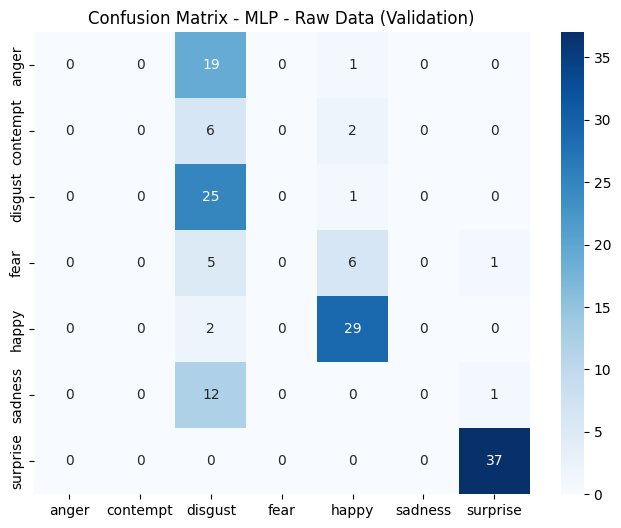


--- MLP - Raw Data (Test) ---
F1 Score: 0.3427
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        21
    contempt       0.00      0.00      0.00         8
     disgust       0.35      1.00      0.52        27
        fear       0.00      0.00      0.00        11
       happy       0.88      0.94      0.91        31
     sadness       0.00      0.00      0.00        12
    surprise       0.97      0.97      0.97        38

    accuracy                           0.63       148
   macro avg       0.31      0.42      0.34       148
weighted avg       0.50      0.63      0.53       148



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


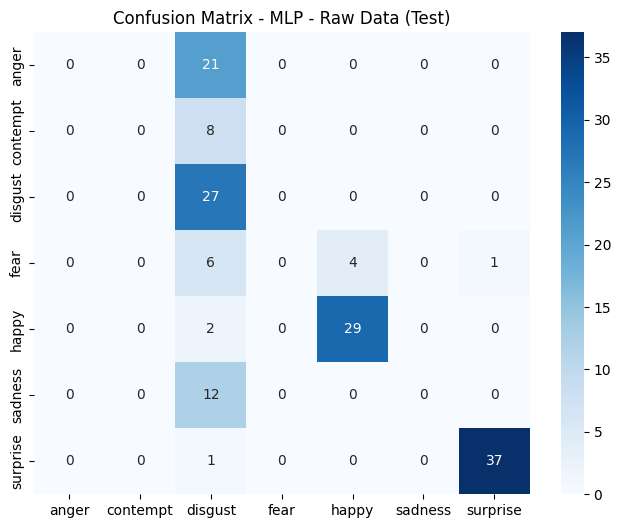

In [12]:
print("--- MLP (Raw Data) ---")
mlp_raw = train_mlp(X_train_raw, y_train, X_val_raw, y_val, input_dim=X_train_raw.shape[1], num_classes=len(label_encoder.classes_))
evaluate_mlp(mlp_raw, X_train_raw, y_train, "MLP - Raw Data (Train)")
evaluate_mlp(mlp_raw, X_val_raw, y_val, "MLP - Raw Data (Validation)")
evaluate_mlp(mlp_raw, X_test_raw, y_test, "MLP - Raw Data (Test)")

# Scaling Experiments

In [13]:
# === SECTION: SCALED DATA ===
print("\n===== SCALED DATA =====")


===== SCALED DATA =====


Decision Tree


--- Decision Tree (Scaled Data) ---

--- Train Set Evaluation: Decision Tree - Scaled Data ---
F1: 1.0000
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00        94
    contempt       1.00      1.00      1.00        38
     disgust       1.00      1.00      1.00       124
        fear       1.00      1.00      1.00        52
       happy       1.00      1.00      1.00       145
     sadness       1.00      1.00      1.00        59
    surprise       1.00      1.00      1.00       174

    accuracy                           1.00       686
   macro avg       1.00      1.00      1.00       686
weighted avg       1.00      1.00      1.00       686



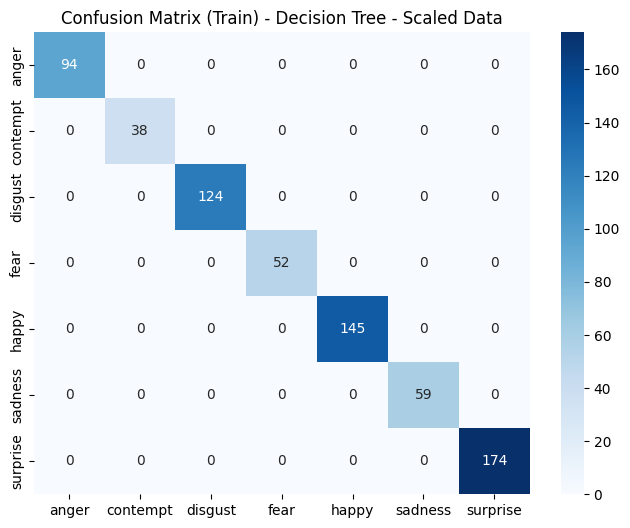


--- Validation Set Evaluation: Decision Tree - Scaled Data ---
F1: 0.8144
              precision    recall  f1-score   support

       anger       0.89      0.85      0.87        20
    contempt       0.75      0.75      0.75         8
     disgust       0.82      0.88      0.85        26
        fear       0.70      0.58      0.64        12
       happy       1.00      0.97      0.98        31
     sadness       0.56      0.69      0.62        13
    surprise       1.00      0.97      0.99        37

    accuracy                           0.87       147
   macro avg       0.82      0.81      0.81       147
weighted avg       0.88      0.87      0.87       147



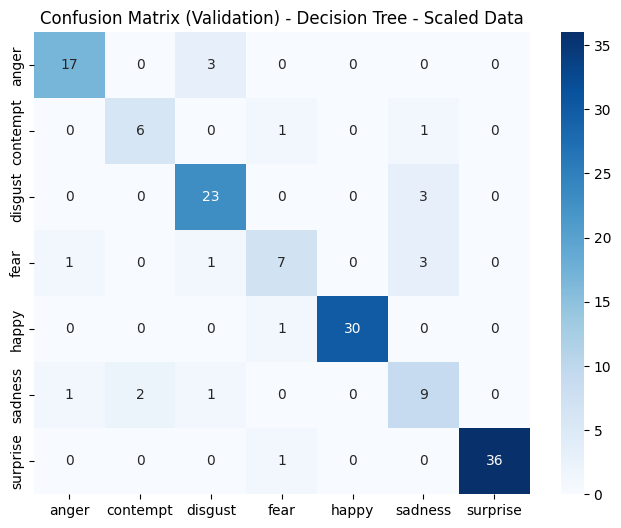


--- Test Set Evaluation: Decision Tree - Scaled Data ---
F1: 0.8069
              precision    recall  f1-score   support

       anger       0.58      0.52      0.55        21
    contempt       0.73      1.00      0.84         8
     disgust       0.80      0.74      0.77        27
        fear       1.00      0.64      0.78        11
       happy       0.94      1.00      0.97        31
     sadness       0.67      0.83      0.74        12
    surprise       1.00      1.00      1.00        38

    accuracy                           0.84       148
   macro avg       0.82      0.82      0.81       148
weighted avg       0.85      0.84      0.84       148



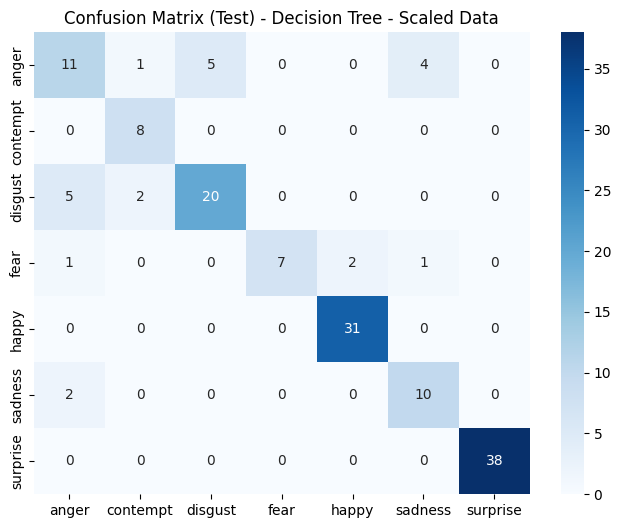

(1.0, 0.8143725632032623, 0.8069435072724547)

In [14]:
# Decision Tree
print("\n--- Decision Tree (Scaled Data) ---")
dt_scaled = DecisionTreeClassifier(random_state=42)
dt_scaled.fit(X_train_scaled, y_train)
full_evaluation(dt_scaled, X_train_scaled, y_train, X_val_scaled, y_val, X_test_scaled, y_test, "Decision Tree - Scaled Data")

Support Vector Machine


--- SVM (Scaled Data) ---

--- Train Set Evaluation: SVM - Scaled Data ---
F1: 0.9121
              precision    recall  f1-score   support

       anger       0.82      0.87      0.85        94
    contempt       0.73      1.00      0.84        38
     disgust       0.96      0.88      0.92       124
        fear       0.96      0.96      0.96        52
       happy       1.00      0.95      0.98       145
     sadness       0.84      0.88      0.86        59
    surprise       1.00      0.97      0.98       174

    accuracy                           0.93       686
   macro avg       0.90      0.93      0.91       686
weighted avg       0.94      0.93      0.93       686



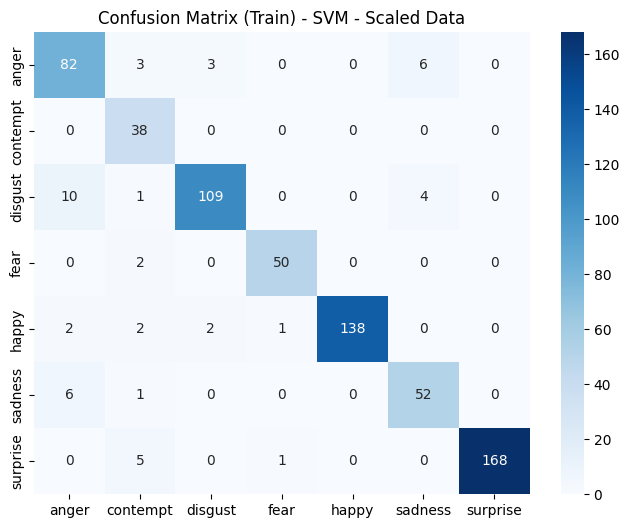


--- Validation Set Evaluation: SVM - Scaled Data ---
F1: 0.8796
              precision    recall  f1-score   support

       anger       0.72      0.90      0.80        20
    contempt       0.80      1.00      0.89         8
     disgust       0.91      0.77      0.83        26
        fear       0.92      0.92      0.92        12
       happy       1.00      0.90      0.95        31
     sadness       0.77      0.77      0.77        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.90       147
   macro avg       0.87      0.89      0.88       147
weighted avg       0.91      0.90      0.90       147



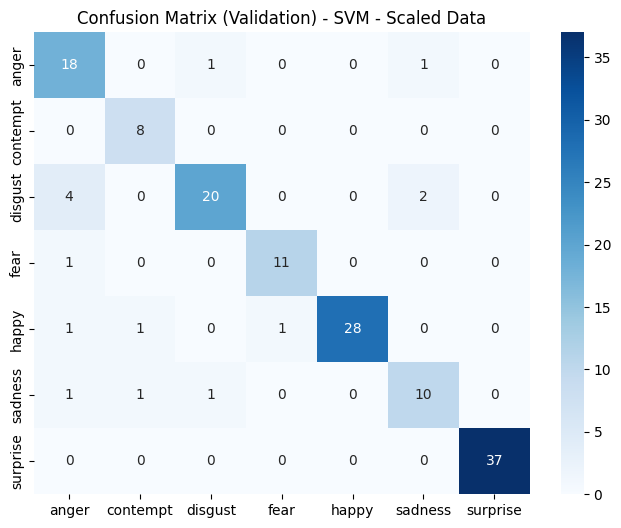


--- Test Set Evaluation: SVM - Scaled Data ---
F1: 0.7938
              precision    recall  f1-score   support

       anger       0.75      0.86      0.80        21
    contempt       0.50      1.00      0.67         8
     disgust       0.95      0.78      0.86        27
        fear       0.78      0.64      0.70        11
       happy       0.97      0.94      0.95        31
     sadness       0.64      0.58      0.61        12
    surprise       1.00      0.95      0.97        38

    accuracy                           0.85       148
   macro avg       0.80      0.82      0.79       148
weighted avg       0.88      0.85      0.86       148



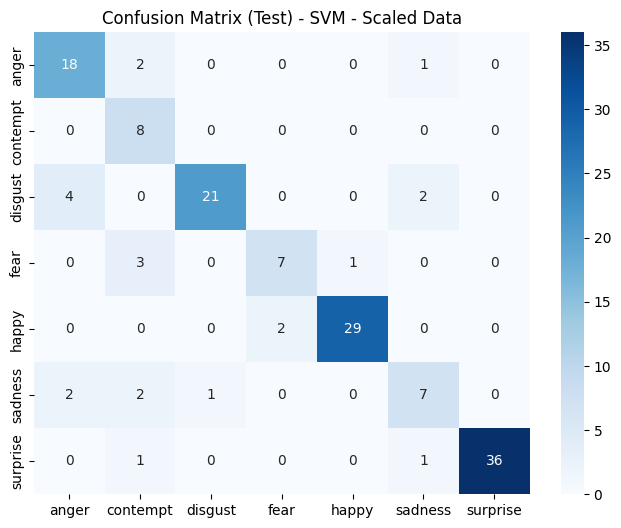

(0.9120764867899889, 0.879610314356077, 0.7937568315839367)

In [15]:
# SVM
print("\n--- SVM (Scaled Data) ---")
svm_scaled = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_scaled.fit(X_train_scaled, y_train)
full_evaluation(svm_scaled, X_train_scaled, y_train, X_val_scaled, y_val, X_test_scaled, y_test, "SVM - Scaled Data")

Multilayer Perceptron

--- MLP (Scaled Data)---
Epoch 100: Validation Acc: 0.8435
Epoch 200: Validation Acc: 0.9048
Epoch 300: Validation Acc: 0.8707
Epoch 400: Validation Acc: 0.8912
Epoch 500: Validation Acc: 0.8367
Epoch 600: Validation Acc: 0.8571
Epoch 700: Validation Acc: 0.8844
Epoch 800: Validation Acc: 0.8844
Epoch 900: Validation Acc: 0.8776
Epoch 1000: Validation Acc: 0.8776

--- MLP - Scaled Data (Train) ---
F1 Score: 0.7932
              precision    recall  f1-score   support

       anger       0.66      0.70      0.68        94
    contempt       0.79      0.39      0.53        38
     disgust       0.84      0.92      0.88       124
        fear       0.95      0.75      0.84        52
       happy       0.93      0.99      0.96       145
     sadness       0.64      0.75      0.69        59
    surprise       0.99      0.97      0.98       174

    accuracy                           0.86       686
   macro avg       0.83      0.78      0.79       686
weighted avg       0.86      0.86      0

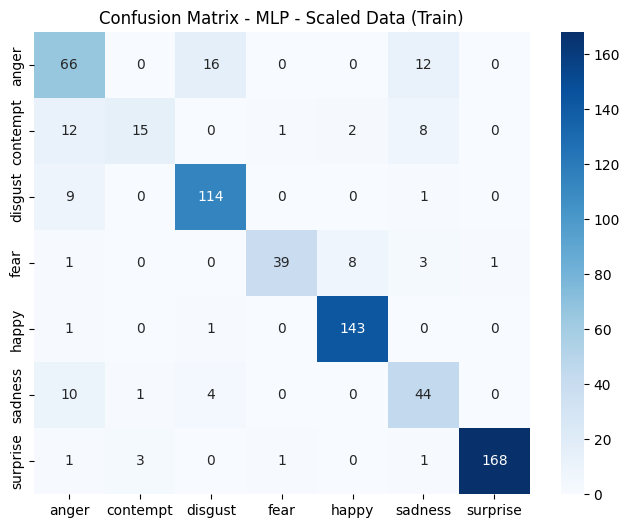


--- MLP - Scaled Data (Validation) ---
F1 Score: 0.8432
              precision    recall  f1-score   support

       anger       0.81      0.65      0.72        20
    contempt       1.00      0.75      0.86         8
     disgust       0.76      0.96      0.85        26
        fear       1.00      0.58      0.74        12
       happy       0.91      0.97      0.94        31
     sadness       0.79      0.85      0.81        13
    surprise       0.97      1.00      0.99        37

    accuracy                           0.88       147
   macro avg       0.89      0.82      0.84       147
weighted avg       0.89      0.88      0.87       147



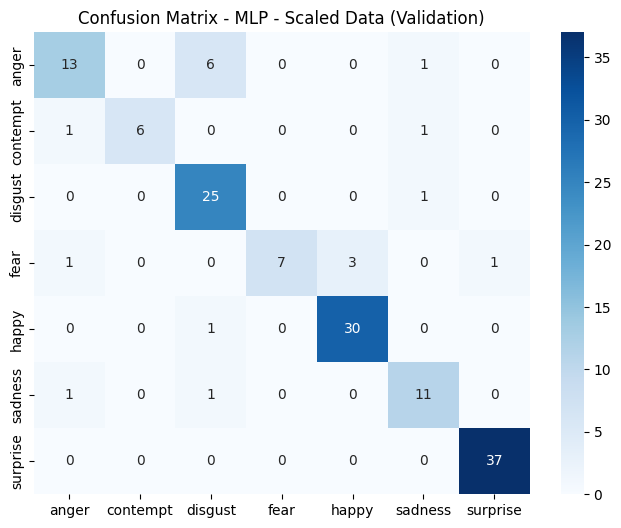


--- MLP - Scaled Data (Test) ---
F1 Score: 0.6587
              precision    recall  f1-score   support

       anger       0.55      0.57      0.56        21
    contempt       1.00      0.25      0.40         8
     disgust       0.81      0.93      0.86        27
        fear       0.71      0.45      0.56        11
       happy       0.91      1.00      0.95        31
     sadness       0.29      0.33      0.31        12
    surprise       0.97      0.97      0.97        38

    accuracy                           0.78       148
   macro avg       0.75      0.64      0.66       148
weighted avg       0.80      0.78      0.77       148



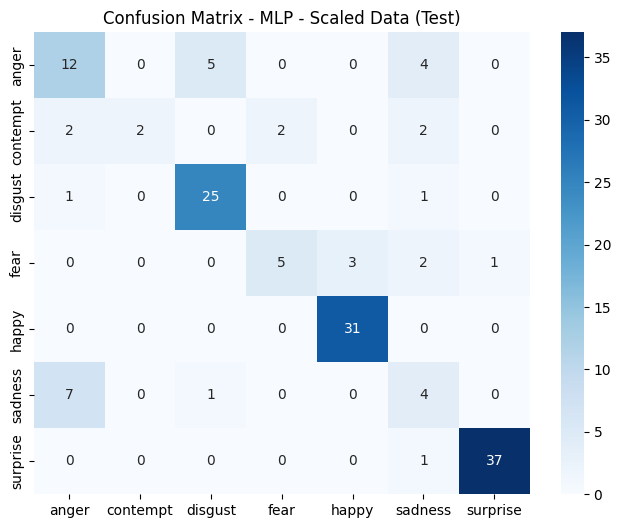

In [16]:
print("--- MLP (Scaled Data)---")
mlp_scaled = train_mlp(X_train_scaled, y_train, X_val_scaled, y_val, input_dim=X_train_scaled.shape[1], num_classes=len(label_encoder.classes_))
evaluate_mlp(mlp_scaled, X_train_scaled, y_train, "MLP - Scaled Data (Train)")
evaluate_mlp(mlp_scaled, X_val_scaled, y_val, "MLP - Scaled Data (Validation)")
evaluate_mlp(mlp_scaled, X_test_scaled, y_test, "MLP - Scaled Data (Test)")

# SMOTE(Synthetic Minority Oversampling Technique) Experiments

In [17]:
# === SECTION: SMOTE DATA ===
print("\n===== SMOTE DATA =====")


===== SMOTE DATA =====


Decision Tree


--- Decision Tree (SMOTE Data) ---

--- Train Set Evaluation: Decision Tree - SMOTE Data ---
F1: 1.0000
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00       174
    contempt       1.00      1.00      1.00       174
     disgust       1.00      1.00      1.00       174
        fear       1.00      1.00      1.00       174
       happy       1.00      1.00      1.00       174
     sadness       1.00      1.00      1.00       174
    surprise       1.00      1.00      1.00       174

    accuracy                           1.00      1218
   macro avg       1.00      1.00      1.00      1218
weighted avg       1.00      1.00      1.00      1218



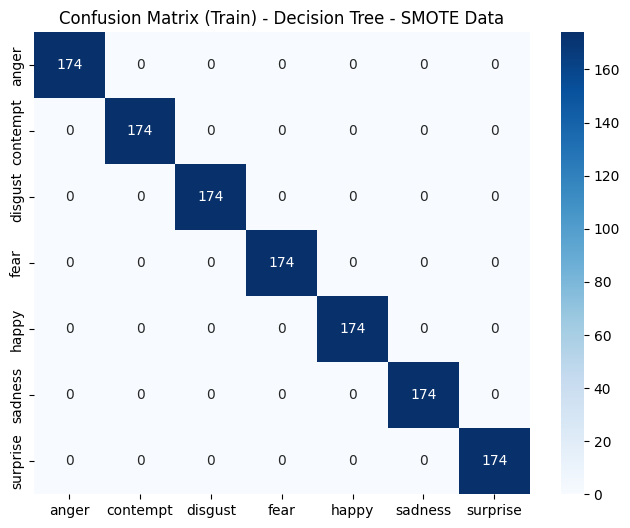


--- Validation Set Evaluation: Decision Tree - SMOTE Data ---
F1: 0.9177
              precision    recall  f1-score   support

       anger       0.88      0.70      0.78        20
    contempt       1.00      1.00      1.00         8
     disgust       0.80      0.92      0.86        26
        fear       0.92      0.92      0.92        12
       happy       1.00      0.97      0.98        31
     sadness       0.86      0.92      0.89        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.93       147
   macro avg       0.92      0.92      0.92       147
weighted avg       0.93      0.93      0.92       147



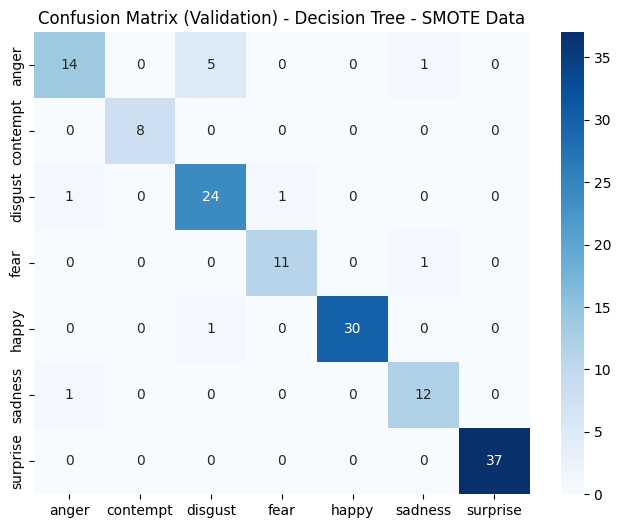


--- Test Set Evaluation: Decision Tree - SMOTE Data ---
F1: 0.8125
              precision    recall  f1-score   support

       anger       0.68      0.71      0.70        21
    contempt       0.58      0.88      0.70         8
     disgust       0.88      0.85      0.87        27
        fear       0.88      0.64      0.74        11
       happy       0.97      1.00      0.98        31
     sadness       0.80      0.67      0.73        12
    surprise       0.97      0.97      0.97        38

    accuracy                           0.86       148
   macro avg       0.82      0.82      0.81       148
weighted avg       0.87      0.86      0.87       148



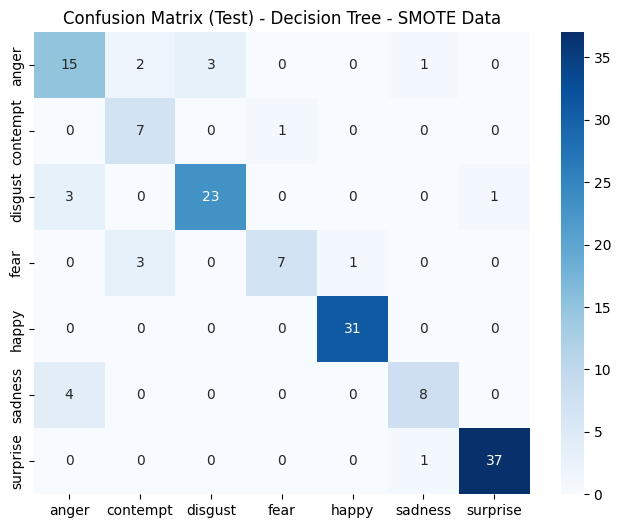

(1.0, 0.9177261068361771, 0.8125035677279604)

In [18]:
# Decision Tree
print("\n--- Decision Tree (SMOTE Data) ---")
dt_smote = DecisionTreeClassifier(random_state=42)
dt_smote.fit(X_train_smote, y_train_smote)
full_evaluation(dt_smote, X_train_smote, y_train_smote, X_val_scaled, y_val, X_test_scaled, y_test, "Decision Tree - SMOTE Data")

Support Vector Machine


--- SVM (SMOTE Data) ---

--- Train Set Evaluation: SVM - SMOTE Data ---
F1: 0.9739
              precision    recall  f1-score   support

       anger       0.90      0.98      0.94       174
    contempt       0.98      0.99      0.99       174
     disgust       0.98      0.95      0.96       174
        fear       0.99      0.99      0.99       174
       happy       1.00      0.98      0.99       174
     sadness       0.98      0.94      0.96       174
    surprise       1.00      0.98      0.99       174

    accuracy                           0.97      1218
   macro avg       0.98      0.97      0.97      1218
weighted avg       0.98      0.97      0.97      1218



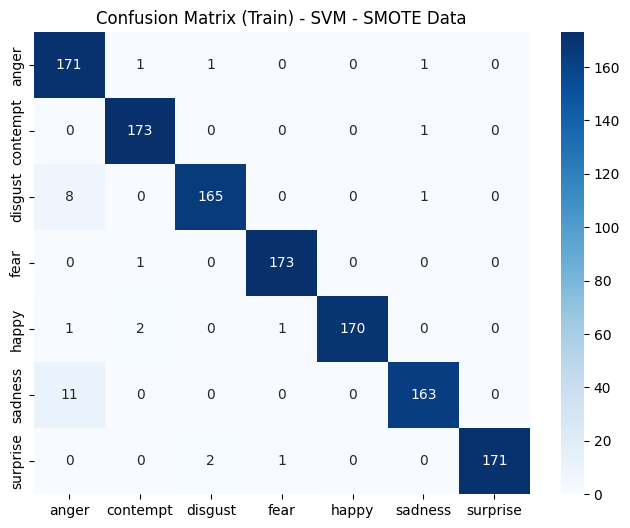


--- Validation Set Evaluation: SVM - SMOTE Data ---
F1: 0.9350
              precision    recall  f1-score   support

       anger       0.86      0.95      0.90        20
    contempt       1.00      0.88      0.93         8
     disgust       1.00      0.96      0.98        26
        fear       0.91      0.83      0.87        12
       happy       0.97      0.97      0.97        31
     sadness       0.86      0.92      0.89        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.95       147
   macro avg       0.94      0.93      0.93       147
weighted avg       0.95      0.95      0.95       147



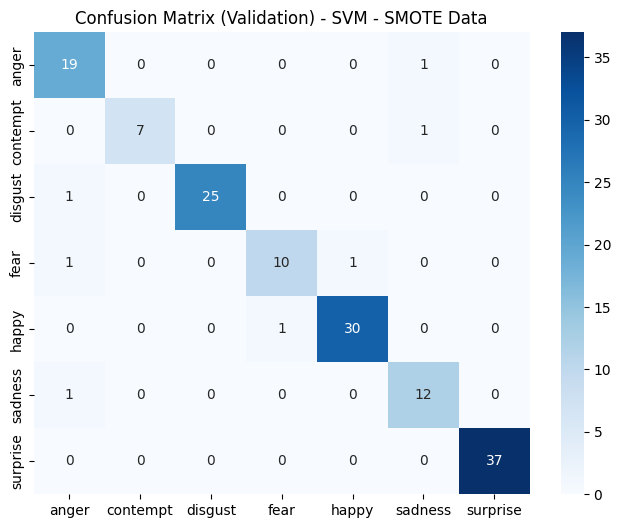


--- Test Set Evaluation: SVM - SMOTE Data ---
F1: 0.8556
              precision    recall  f1-score   support

       anger       0.76      0.90      0.83        21
    contempt       0.58      0.88      0.70         8
     disgust       0.96      0.85      0.90        27
        fear       0.88      0.64      0.74        11
       happy       0.97      0.97      0.97        31
     sadness       0.91      0.83      0.87        12
    surprise       1.00      0.97      0.99        38

    accuracy                           0.90       148
   macro avg       0.86      0.86      0.86       148
weighted avg       0.91      0.90      0.90       148



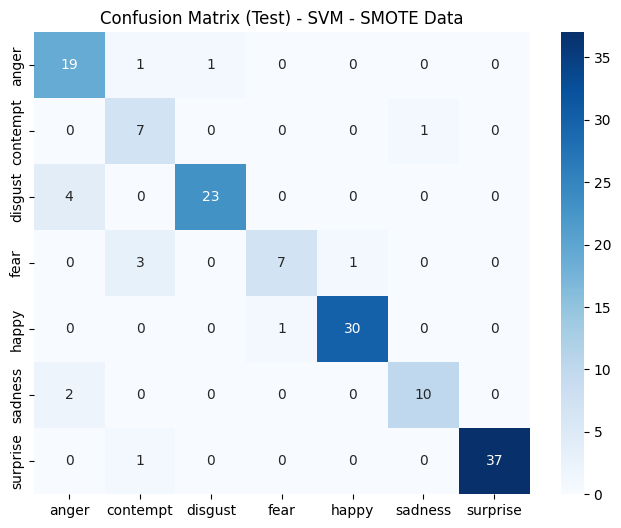

(0.9739367927927185, 0.9349547766745783, 0.855551952234352)

In [19]:
# SVM
print("\n--- SVM (SMOTE Data) ---")
svm_smote = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_smote.fit(X_train_smote, y_train_smote)
full_evaluation(svm_smote, X_train_smote, y_train_smote, X_val_scaled, y_val, X_test_scaled, y_test, "SVM - SMOTE Data")

Multilayer Perceptron

--- MLP ---
Epoch 100: Validation Acc: 0.8844
Epoch 200: Validation Acc: 0.8639
Epoch 300: Validation Acc: 0.8571
Epoch 400: Validation Acc: 0.8435
Epoch 500: Validation Acc: 0.8639
Epoch 600: Validation Acc: 0.8844
Epoch 700: Validation Acc: 0.8571
Epoch 800: Validation Acc: 0.8707
Epoch 900: Validation Acc: 0.8299
Epoch 1000: Validation Acc: 0.8571

--- MLP - SMOTE Data (Train) ---
F1 Score: 0.8518
              precision    recall  f1-score   support

       anger       0.66      0.78      0.72       174
    contempt       0.80      0.80      0.80       174
     disgust       0.82      0.82      0.82       174
        fear       0.97      0.83      0.90       174
       happy       0.96      0.98      0.97       174
     sadness       0.81      0.77      0.79       174
    surprise       0.99      0.97      0.98       174

    accuracy                           0.85      1218
   macro avg       0.86      0.85      0.85      1218
weighted avg       0.86      0.85      0.85      1218


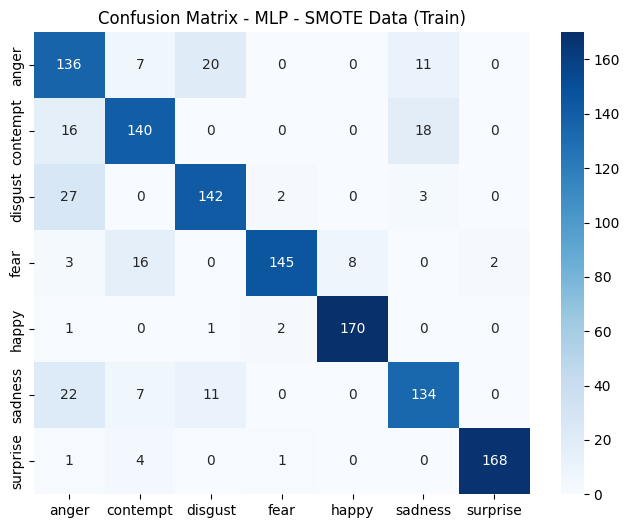


--- MLP - SMOTE Data (Validation) ---
F1 Score: 0.8060
              precision    recall  f1-score   support

       anger       0.70      0.80      0.74        20
    contempt       0.64      0.88      0.74         8
     disgust       0.81      0.81      0.81        26
        fear       0.86      0.50      0.63        12
       happy       0.94      0.97      0.95        31
     sadness       0.90      0.69      0.78        13
    surprise       0.97      1.00      0.99        37

    accuracy                           0.86       147
   macro avg       0.83      0.81      0.81       147
weighted avg       0.86      0.86      0.85       147



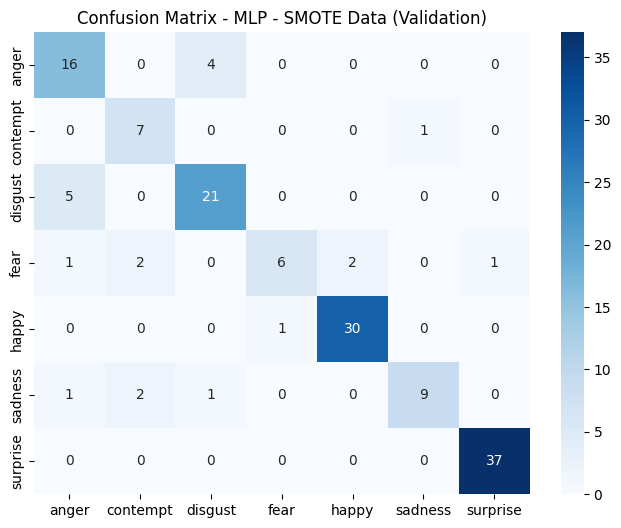


--- MLP - SMOTE Data (Test) ---
F1 Score: 0.6517
              precision    recall  f1-score   support

       anger       0.52      0.62      0.57        21
    contempt       0.50      0.62      0.56         8
     disgust       0.81      0.78      0.79        27
        fear       0.50      0.27      0.35        11
       happy       0.94      0.94      0.94        31
     sadness       0.38      0.42      0.40        12
    surprise       0.97      0.95      0.96        38

    accuracy                           0.76       148
   macro avg       0.66      0.66      0.65       148
weighted avg       0.76      0.76      0.76       148



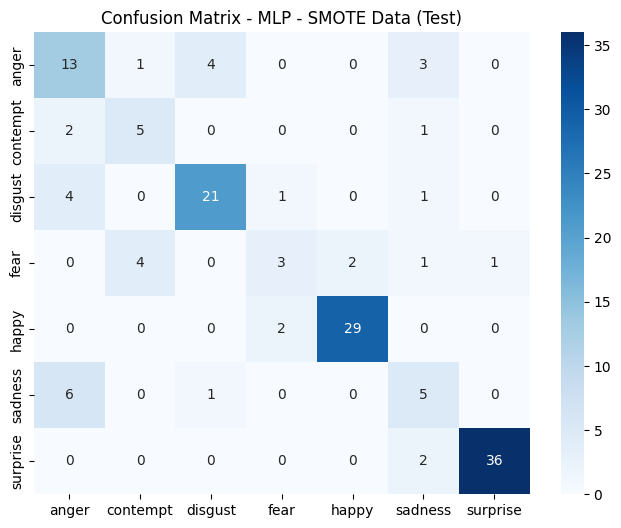

In [20]:
print("--- MLP ---")
mlp_smote = train_mlp(X_train_smote, y_train_smote, X_val_scaled, y_val, input_dim=X_train_smote.shape[1], num_classes=len(label_encoder.classes_))
evaluate_mlp(mlp_smote, X_train_smote, y_train_smote, "MLP - SMOTE Data (Train)")
evaluate_mlp(mlp_smote, X_val_scaled, y_val, "MLP - SMOTE Data (Validation)")
evaluate_mlp(mlp_smote, X_test_scaled, y_test, "MLP - SMOTE Data (Test)")

# SMOTE and Feature Selection All

In [ ]:
# === SECTION: SMOTE AND ALL FEATURES DATA ===
print("\n===== SMOTE AND ALL FEATURES DATA =====")


===== SMOTE AND ALL FEATURES DATA =====


Decision Tree


--- Decision Tree (SMOTE - ALL Data) ---

--- Train Set Evaluation: Decision Tree - SMOTE - All Data ---
F1: 1.0000
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00       174
    contempt       1.00      1.00      1.00       174
     disgust       1.00      1.00      1.00       174
        fear       1.00      1.00      1.00       174
       happy       1.00      1.00      1.00       174
     sadness       1.00      1.00      1.00       174
    surprise       1.00      1.00      1.00       174

    accuracy                           1.00      1218
   macro avg       1.00      1.00      1.00      1218
weighted avg       1.00      1.00      1.00      1218



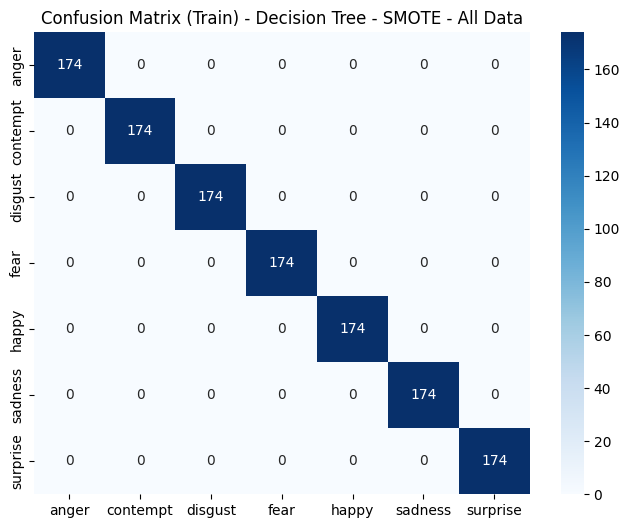


--- Validation Set Evaluation: Decision Tree - SMOTE - All Data ---
F1: 0.9177
              precision    recall  f1-score   support

       anger       0.88      0.70      0.78        20
    contempt       1.00      1.00      1.00         8
     disgust       0.80      0.92      0.86        26
        fear       0.92      0.92      0.92        12
       happy       1.00      0.97      0.98        31
     sadness       0.86      0.92      0.89        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.93       147
   macro avg       0.92      0.92      0.92       147
weighted avg       0.93      0.93      0.92       147



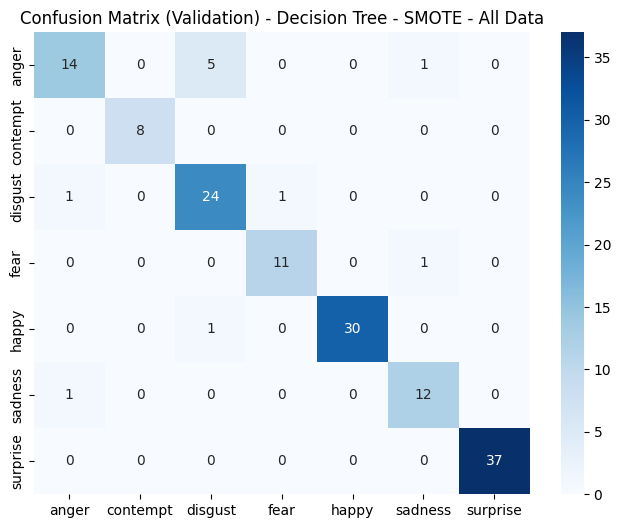


--- Test Set Evaluation: Decision Tree - SMOTE - All Data ---
F1: 0.8125
              precision    recall  f1-score   support

       anger       0.68      0.71      0.70        21
    contempt       0.58      0.88      0.70         8
     disgust       0.88      0.85      0.87        27
        fear       0.88      0.64      0.74        11
       happy       0.97      1.00      0.98        31
     sadness       0.80      0.67      0.73        12
    surprise       0.97      0.97      0.97        38

    accuracy                           0.86       148
   macro avg       0.82      0.82      0.81       148
weighted avg       0.87      0.86      0.87       148



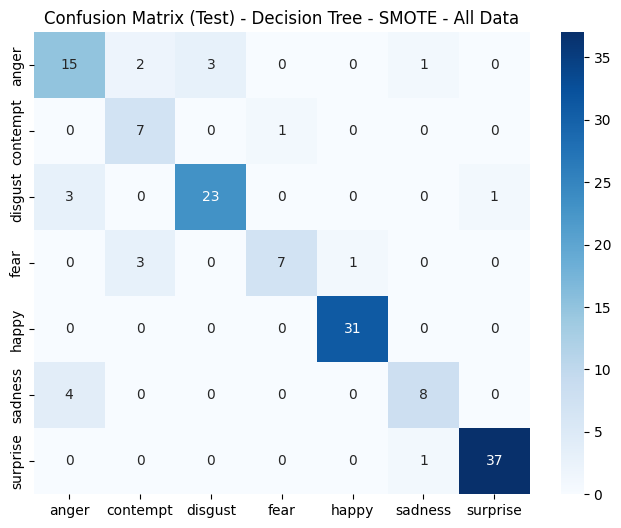

(1.0, 0.9177261068361771, 0.8125035677279604)

In [ ]:
# Decision Tree
print("\n--- Decision Tree (SMOTE - ALL Data) ---")
dt_all = DecisionTreeClassifier(random_state=42)
dt_all.fit(X_train_all, y_train_smote)
full_evaluation(dt_all, X_train_all, y_train_smote, X_val_all, y_val, X_test_all, y_test, "Decision Tree - SMOTE - All Data")

Support Vector Machine


--- SVM (SMOTE - All Data) ---

--- Train Set Evaluation: SVM - SMOTE - All Data ---
F1: 0.9739
              precision    recall  f1-score   support

       anger       0.90      0.98      0.94       174
    contempt       0.98      0.99      0.99       174
     disgust       0.98      0.95      0.96       174
        fear       0.99      0.99      0.99       174
       happy       1.00      0.98      0.99       174
     sadness       0.98      0.94      0.96       174
    surprise       1.00      0.98      0.99       174

    accuracy                           0.97      1218
   macro avg       0.98      0.97      0.97      1218
weighted avg       0.98      0.97      0.97      1218



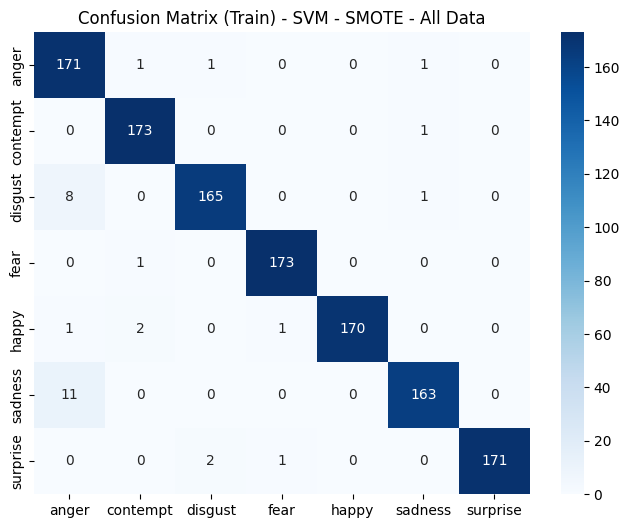


--- Validation Set Evaluation: SVM - SMOTE - All Data ---
F1: 0.9350
              precision    recall  f1-score   support

       anger       0.86      0.95      0.90        20
    contempt       1.00      0.88      0.93         8
     disgust       1.00      0.96      0.98        26
        fear       0.91      0.83      0.87        12
       happy       0.97      0.97      0.97        31
     sadness       0.86      0.92      0.89        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.95       147
   macro avg       0.94      0.93      0.93       147
weighted avg       0.95      0.95      0.95       147



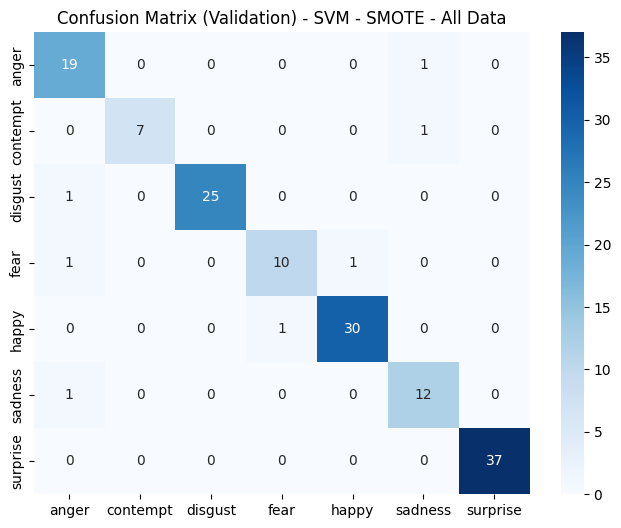


--- Test Set Evaluation: SVM - SMOTE - All Data ---
F1: 0.8556
              precision    recall  f1-score   support

       anger       0.76      0.90      0.83        21
    contempt       0.58      0.88      0.70         8
     disgust       0.96      0.85      0.90        27
        fear       0.88      0.64      0.74        11
       happy       0.97      0.97      0.97        31
     sadness       0.91      0.83      0.87        12
    surprise       1.00      0.97      0.99        38

    accuracy                           0.90       148
   macro avg       0.86      0.86      0.86       148
weighted avg       0.91      0.90      0.90       148



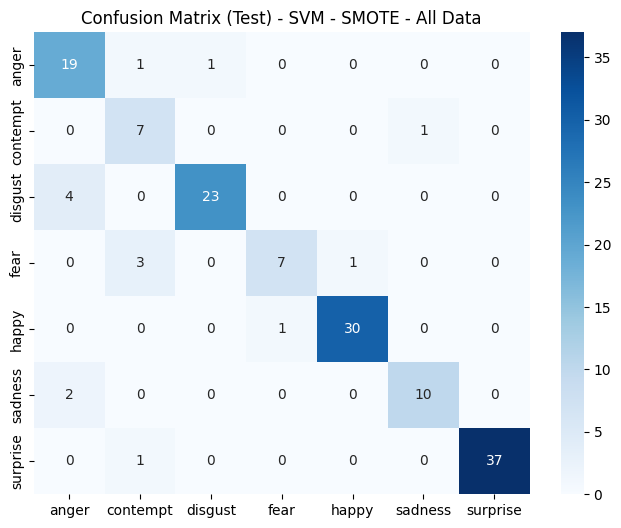

(0.9739367927927185, 0.9349547766745783, 0.855551952234352)

In [ ]:
# SVM
print("\n--- SVM (SMOTE - All Data) ---")
svm_all = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_all.fit(X_train_all, y_train_smote)
full_evaluation(svm_all, X_train_all, y_train_smote, X_val_all, y_val, X_test_all, y_test, "SVM - SMOTE - All Data")

Multilayer Perceptron

--- MLP (SMOTE - All Data) ---
Epoch 100: Validation Acc: 0.8776
Epoch 200: Validation Acc: 0.8776
Epoch 300: Validation Acc: 0.8435
Epoch 400: Validation Acc: 0.8707
Epoch 500: Validation Acc: 0.8571
Epoch 600: Validation Acc: 0.8707
Epoch 700: Validation Acc: 0.8844
Epoch 800: Validation Acc: 0.8367
Epoch 900: Validation Acc: 0.8503
Epoch 1000: Validation Acc: 0.8231

--- MLP - Feature All Data (Train) ---
F1 Score: 0.8449
              precision    recall  f1-score   support

       anger       0.80      0.58      0.67       174
    contempt       0.71      0.91      0.80       174
     disgust       0.84      0.80      0.82       174
        fear       0.97      0.84      0.90       174
       happy       0.96      0.97      0.97       174
     sadness       0.71      0.86      0.78       174
    surprise       1.00      0.95      0.98       174

    accuracy                           0.85      1218
   macro avg       0.86      0.85      0.84      1218
weighted avg       0.86      

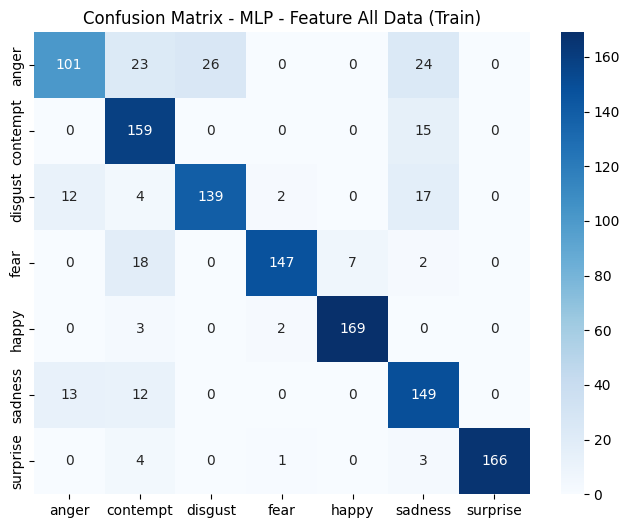


--- MLP - Feature All Data (Validation) ---
F1 Score: 0.7523
              precision    recall  f1-score   support

       anger       0.89      0.40      0.55        20
    contempt       0.44      0.88      0.58         8
     disgust       0.77      0.88      0.82        26
        fear       1.00      0.58      0.74        12
       happy       0.94      0.97      0.95        31
     sadness       0.56      0.69      0.62        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.82       147
   macro avg       0.80      0.77      0.75       147
weighted avg       0.86      0.82      0.82       147



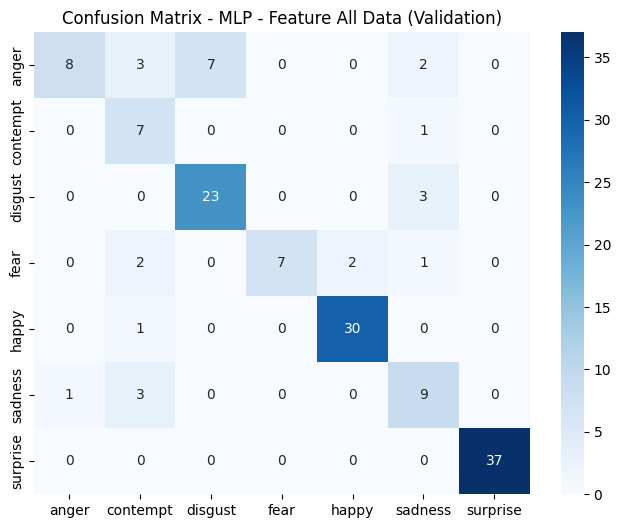


--- MLP - Feature All Data (Test) ---
F1 Score: 0.7129
              precision    recall  f1-score   support

       anger       0.71      0.48      0.57        21
    contempt       0.47      1.00      0.64         8
     disgust       0.85      0.81      0.83        27
        fear       0.71      0.45      0.56        11
       happy       0.97      0.97      0.97        31
     sadness       0.39      0.58      0.47        12
    surprise       1.00      0.92      0.96        38

    accuracy                           0.79       148
   macro avg       0.73      0.75      0.71       148
weighted avg       0.83      0.79      0.80       148



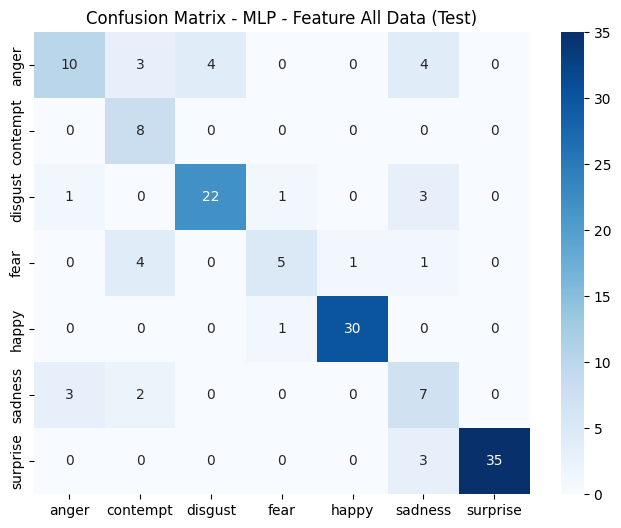

In [ ]:
print("--- MLP (SMOTE - All Data) ---")
mlp_all = train_mlp(X_train_all, y_train_smote, X_val_all, y_val, input_dim=X_train_all.shape[1], num_classes=len(label_encoder.classes_))
evaluate_mlp(mlp_all, X_train_all, y_train_smote, "MLP - Feature All Data (Train)")
evaluate_mlp(mlp_all, X_val_all, y_val, "MLP - Feature All Data (Validation)")
evaluate_mlp(mlp_all, X_test_all, y_test, "MLP - Feature All Data (Test)")

# SMOTE and Feature Selection Top 10

In [ ]:
# === SECTION: SMOTE AND TOP 10 FEATURES DATA ===
print("\n===== SMOTE AND TOP 10 FEATURES DATA =====")


===== SMOTE AND TOP 10 FEATURES DATA =====


Decision Tree


--- Decision Tree (SMOTE - Top 10) Data ---

--- Train Set Evaluation: Decision Tree - SMOTE - Top 10 Data ---
F1: 1.0000
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00       174
    contempt       1.00      1.00      1.00       174
     disgust       1.00      1.00      1.00       174
        fear       1.00      1.00      1.00       174
       happy       1.00      1.00      1.00       174
     sadness       1.00      1.00      1.00       174
    surprise       1.00      1.00      1.00       174

    accuracy                           1.00      1218
   macro avg       1.00      1.00      1.00      1218
weighted avg       1.00      1.00      1.00      1218



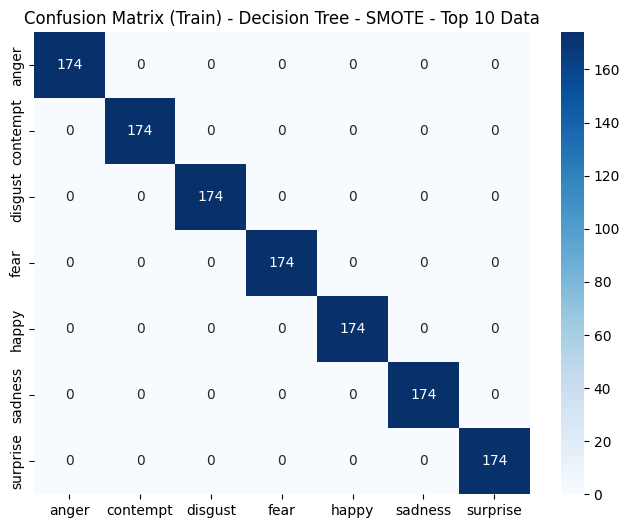


--- Validation Set Evaluation: Decision Tree - SMOTE - Top 10 Data ---
F1: 0.8131
              precision    recall  f1-score   support

       anger       0.70      0.80      0.74        20
    contempt       0.75      0.75      0.75         8
     disgust       0.92      0.85      0.88        26
        fear       0.90      0.75      0.82        12
       happy       0.91      0.94      0.92        31
     sadness       0.57      0.62      0.59        13
    surprise       1.00      0.97      0.99        37

    accuracy                           0.86       147
   macro avg       0.82      0.81      0.81       147
weighted avg       0.86      0.86      0.86       147



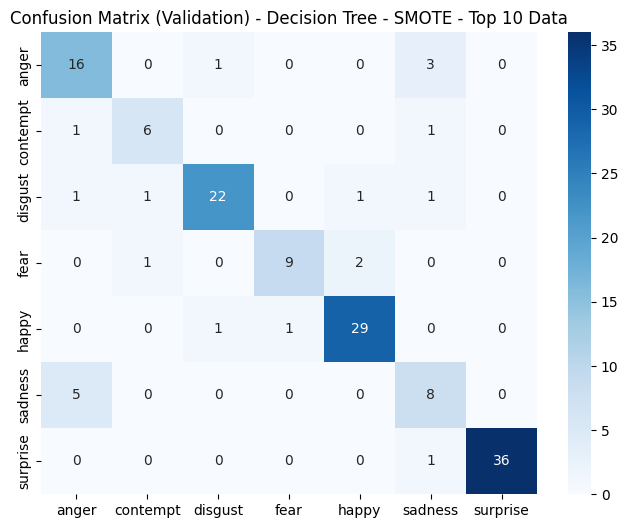


--- Test Set Evaluation: Decision Tree - SMOTE - Top 10 Data ---
F1: 0.7741
              precision    recall  f1-score   support

       anger       0.64      0.67      0.65        21
    contempt       0.50      0.62      0.56         8
     disgust       0.92      0.85      0.88        27
        fear       0.70      0.64      0.67        11
       happy       0.97      0.90      0.93        31
     sadness       0.67      0.83      0.74        12
    surprise       1.00      0.97      0.99        38

    accuracy                           0.84       148
   macro avg       0.77      0.78      0.77       148
weighted avg       0.85      0.84      0.84       148



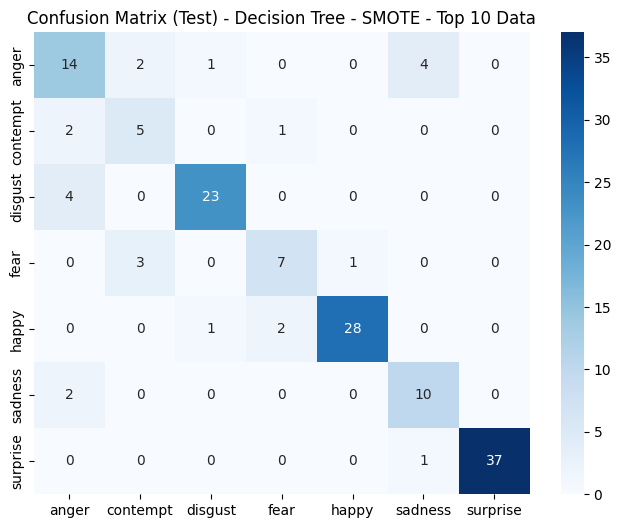

(1.0, 0.8131281068262819, 0.7741058768965745)

In [ ]:
# Decision Tree
print("\n--- Decision Tree (SMOTE - Top 10) Data ---")
dt_top10 = DecisionTreeClassifier(random_state=42)
dt_top10 .fit(X_train_top10 , y_train_smote)
full_evaluation(dt_top10 , X_train_top10, y_train_smote, X_val_top10 , y_val, X_test_top10 , y_test, "Decision Tree - SMOTE - Top 10 Data")

Support Vector Machine


--- SVM (SMOTE - Top 10) Data ---

--- Train Set Evaluation: SVM - SMOTE - Top 10 Data ---
F1: 0.9033
              precision    recall  f1-score   support

       anger       0.81      0.83      0.82       174
    contempt       0.85      0.86      0.86       174
     disgust       0.91      0.88      0.89       174
        fear       0.96      0.95      0.96       174
       happy       1.00      0.95      0.98       174
     sadness       0.80      0.87      0.83       174
    surprise       1.00      0.98      0.99       174

    accuracy                           0.90      1218
   macro avg       0.91      0.90      0.90      1218
weighted avg       0.91      0.90      0.90      1218



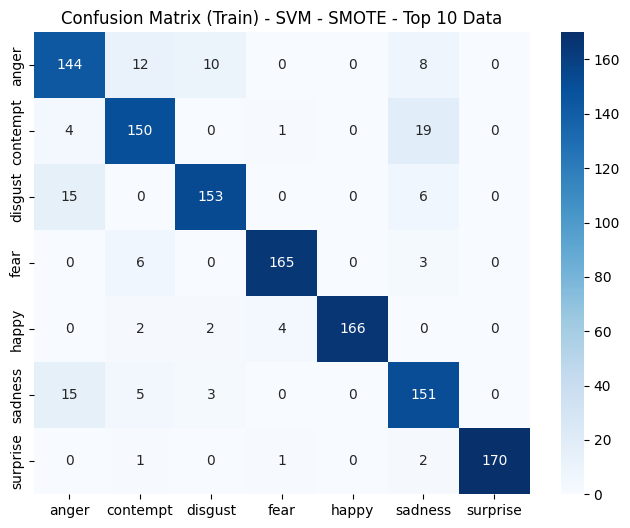


--- Validation Set Evaluation: SVM - SMOTE - Top 10 Data ---
F1: 0.8253
              precision    recall  f1-score   support

       anger       0.70      0.80      0.74        20
    contempt       0.75      0.75      0.75         8
     disgust       0.80      0.77      0.78        26
        fear       0.89      0.67      0.76        12
       happy       0.97      0.94      0.95        31
     sadness       0.73      0.85      0.79        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.86       147
   macro avg       0.83      0.82      0.83       147
weighted avg       0.87      0.86      0.86       147



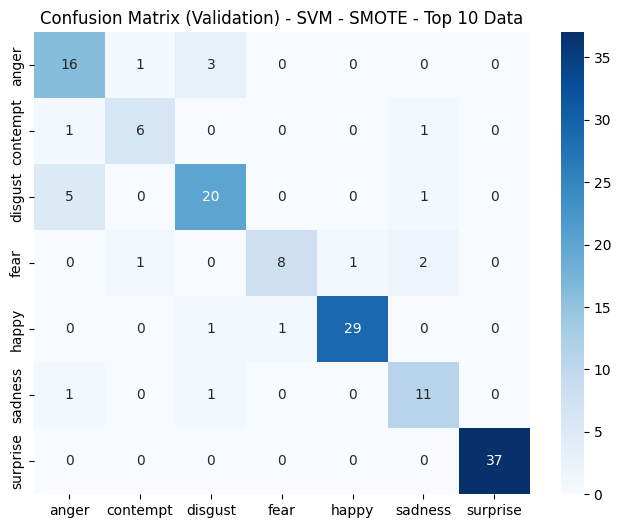


--- Test Set Evaluation: SVM - SMOTE - Top 10 Data ---
F1: 0.7481
              precision    recall  f1-score   support

       anger       0.62      0.71      0.67        21
    contempt       0.50      0.75      0.60         8
     disgust       0.88      0.81      0.85        27
        fear       0.78      0.64      0.70        11
       happy       0.97      0.94      0.95        31
     sadness       0.50      0.50      0.50        12
    surprise       1.00      0.95      0.97        38

    accuracy                           0.82       148
   macro avg       0.75      0.76      0.75       148
weighted avg       0.83      0.82      0.82       148



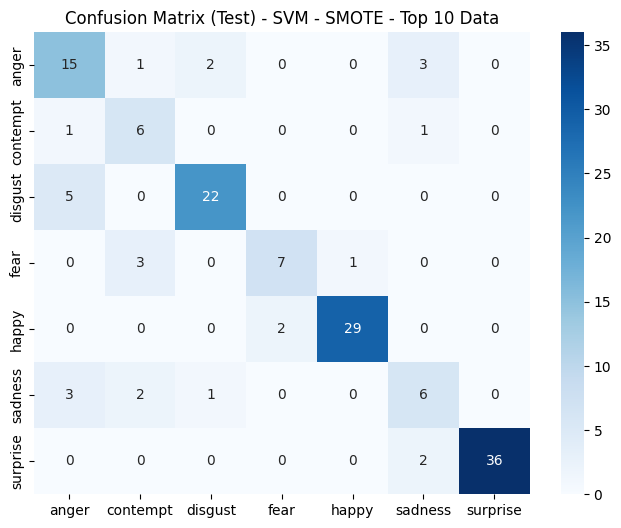

(0.903340265811991, 0.8252769273931456, 0.7480875939892332)

In [ ]:
# SVM
print("\n--- SVM (SMOTE - Top 10) Data ---")
svm_top10 = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_top10.fit(X_train_top10, y_train_smote)
full_evaluation(svm_top10, X_train_top10, y_train_smote, X_val_top10, y_val, X_test_top10, y_test, "SVM - SMOTE - Top 10 Data")

Multilayer Perceptron

--- MLP (SMOTE - Top 10) Data ---
Epoch 100: Validation Acc: 0.8299
Epoch 200: Validation Acc: 0.8163
Epoch 300: Validation Acc: 0.8163
Epoch 400: Validation Acc: 0.8095
Epoch 500: Validation Acc: 0.8299
Epoch 600: Validation Acc: 0.8367
Epoch 700: Validation Acc: 0.7959
Epoch 800: Validation Acc: 0.8163
Epoch 900: Validation Acc: 0.8231
Epoch 1000: Validation Acc: 0.8095

--- MLP - Feature Top 10 Data (Train) ---
F1 Score: 0.8035
              precision    recall  f1-score   support

       anger       0.57      0.66      0.61       174
    contempt       0.72      0.79      0.76       174
     disgust       0.78      0.80      0.79       174
        fear       0.93      0.79      0.86       174
       happy       0.97      0.95      0.96       174
     sadness       0.70      0.64      0.67       174
    surprise       0.99      0.96      0.98       174

    accuracy                           0.80      1218
   macro avg       0.81      0.80      0.80      1218
weighted avg       0.81

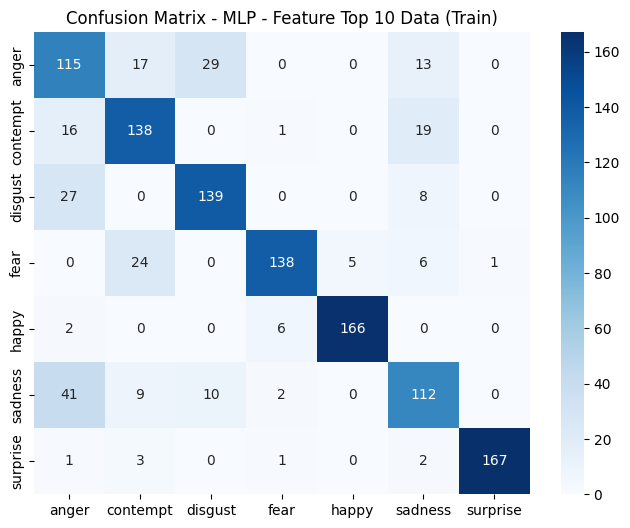


--- MLP - Feature Top 10 Data (Validation) ---
F1 Score: 0.7578
              precision    recall  f1-score   support

       anger       0.54      0.65      0.59        20
    contempt       0.64      0.88      0.74         8
     disgust       0.73      0.73      0.73        26
        fear       0.88      0.58      0.70        12
       happy       0.97      0.94      0.95        31
     sadness       0.70      0.54      0.61        13
    surprise       0.97      1.00      0.99        37

    accuracy                           0.81       147
   macro avg       0.77      0.76      0.76       147
weighted avg       0.82      0.81      0.81       147



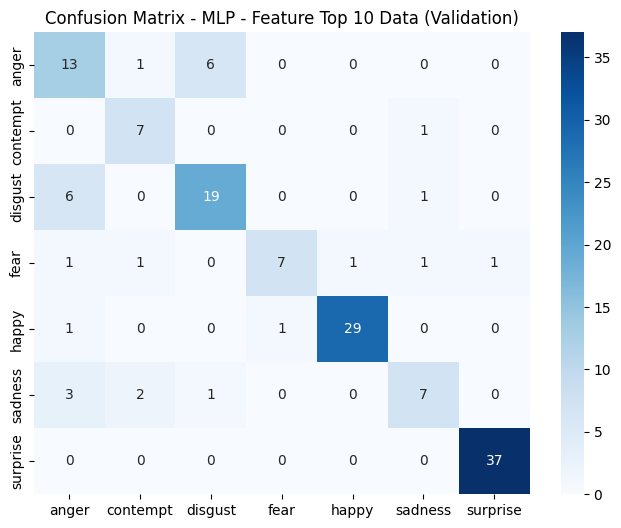


--- MLP - Feature Top 10 Data (Test) ---
F1 Score: 0.6643
              precision    recall  f1-score   support

       anger       0.52      0.71      0.60        21
    contempt       0.46      0.75      0.57         8
     disgust       0.88      0.81      0.85        27
        fear       0.62      0.45      0.53        11
       happy       0.97      0.90      0.93        31
     sadness       0.25      0.17      0.20        12
    surprise       1.00      0.95      0.97        38

    accuracy                           0.77       148
   macro avg       0.67      0.68      0.66       148
weighted avg       0.78      0.77      0.77       148



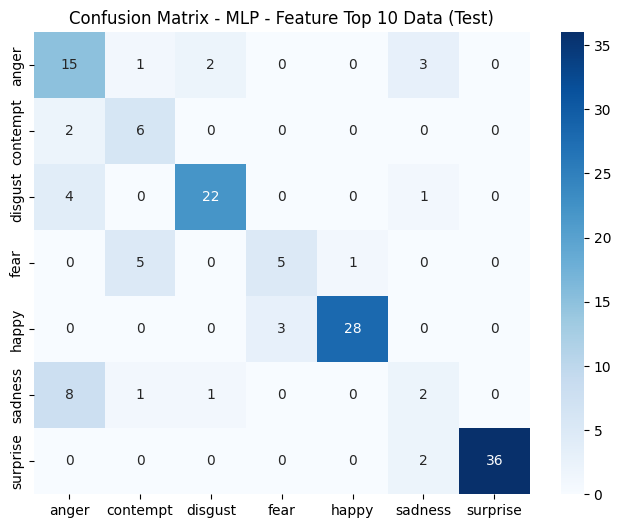

In [ ]:
print("--- MLP (SMOTE - Top 10) Data ---")
mlp_top10 = train_mlp(X_train_top10, y_train_smote, X_val_top10, y_val, input_dim=X_train_top10.shape[1], num_classes=len(label_encoder.classes_))
evaluate_mlp(mlp_top10, X_train_top10, y_train_smote, "MLP - Feature Top 10 Data (Train)")
evaluate_mlp(mlp_top10, X_val_top10, y_val, "MLP - Feature Top 10 Data (Validation)")
evaluate_mlp(mlp_top10, X_test_top10, y_test, "MLP - Feature Top 10 Data (Test)")

# Best Tuned Experiments

In [ ]:
# === SECTION: BEST HYPERPARAMETER TUNED ===
print("\n===== BEST HYPERPARAMETER TUNED =====")


===== BEST HYPERPARAMETER TUNED =====


Decision Tree

Best Decision Tree params: {'criterion': 'entropy', 'max_depth': 10, 'splitter': 'best'}

--- Train Set Evaluation: Decision Tree - GridSearchCV Tuned ---
F1: 0.9992
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00       174
    contempt       1.00      1.00      1.00       174
     disgust       1.00      0.99      1.00       174
        fear       1.00      1.00      1.00       174
       happy       1.00      1.00      1.00       174
     sadness       0.99      1.00      1.00       174
    surprise       1.00      1.00      1.00       174

    accuracy                           1.00      1218
   macro avg       1.00      1.00      1.00      1218
weighted avg       1.00      1.00      1.00      1218



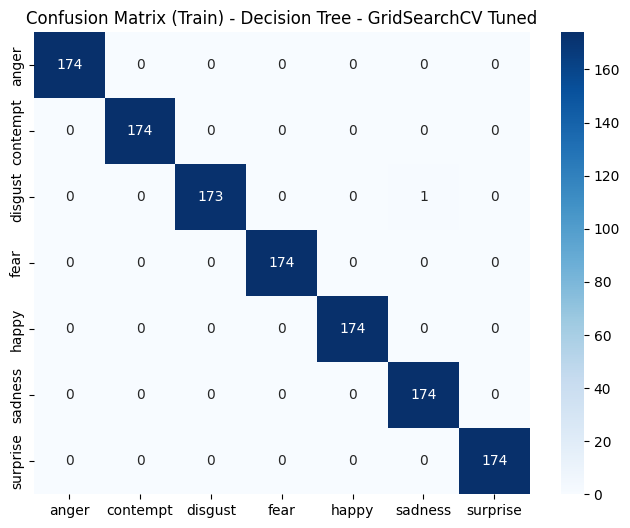


--- Validation Set Evaluation: Decision Tree - GridSearchCV Tuned ---
F1: 0.8378
              precision    recall  f1-score   support

       anger       0.79      0.75      0.77        20
    contempt       0.78      0.88      0.82         8
     disgust       0.91      0.81      0.86        26
        fear       0.80      0.67      0.73        12
       happy       0.97      0.97      0.97        31
     sadness       0.65      0.85      0.73        13
    surprise       0.97      1.00      0.99        37

    accuracy                           0.88       147
   macro avg       0.84      0.84      0.84       147
weighted avg       0.88      0.88      0.88       147



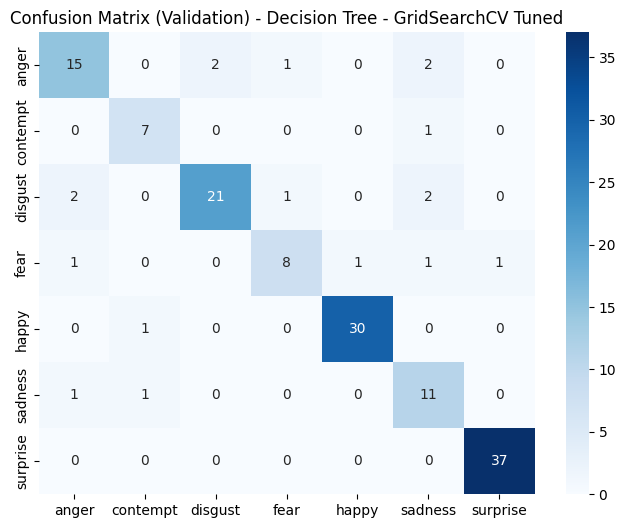


--- Test Set Evaluation: Decision Tree - GridSearchCV Tuned ---
F1: 0.8317
              precision    recall  f1-score   support

       anger       0.79      0.90      0.84        21
    contempt       0.78      0.88      0.82         8
     disgust       0.96      0.89      0.92        27
        fear       0.86      0.55      0.67        11
       happy       0.91      0.97      0.94        31
     sadness       0.62      0.67      0.64        12
    surprise       1.00      0.97      0.99        38

    accuracy                           0.89       148
   macro avg       0.84      0.83      0.83       148
weighted avg       0.89      0.89      0.88       148



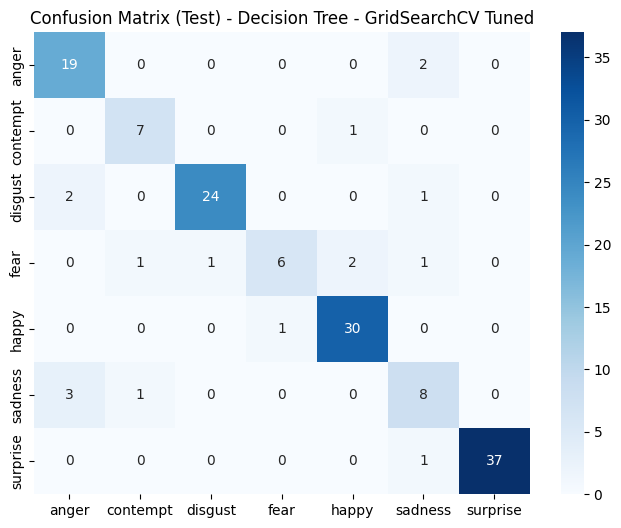

(0.9991789751581004, 0.837845385842133, 0.8316977303742007)

In [ ]:
# === GridSearchCV for Decision Tree ===
#Fine tune hyperparameters for the data set
dt_param_grid = {
    'splitter': ['best', 'random'],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': range(1, 20, 1)
    }

clf = DecisionTreeClassifier(random_state=1)

dt_grid = GridSearchCV(estimator=clf, param_grid = dt_param_grid)

#dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid.fit(X_train_all, y_train_smote)
print('Best Decision Tree params:', dt_grid.best_params_)
full_evaluation(dt_grid.best_estimator_, X_train_all, y_train_smote, X_val_all, y_val, X_test_all, y_test, "Decision Tree - GridSearchCV Tuned")

Support Vector Machine

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best SVM params: {'C': 50, 'gamma': 'scale', 'kernel': 'rbf'}

--- Train Set Evaluation: SVM - GridSearchCV Tuned ---
F1: 1.0000
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00       174
    contempt       1.00      1.00      1.00       174
     disgust       1.00      1.00      1.00       174
        fear       1.00      1.00      1.00       174
       happy       1.00      1.00      1.00       174
     sadness       1.00      1.00      1.00       174
    surprise       1.00      1.00      1.00       174

    accuracy                           1.00      1218
   macro avg       1.00      1.00      1.00      1218
weighted avg       1.00      1.00      1.00      1218



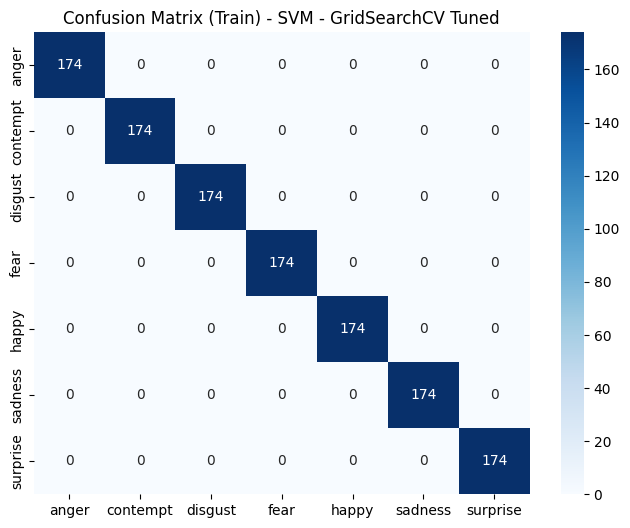


--- Validation Set Evaluation: SVM - GridSearchCV Tuned ---
F1: 0.9903
              precision    recall  f1-score   support

       anger       0.95      1.00      0.98        20
    contempt       1.00      1.00      1.00         8
     disgust       1.00      1.00      1.00        26
        fear       1.00      0.92      0.96        12
       happy       1.00      1.00      1.00        31
     sadness       1.00      1.00      1.00        13
    surprise       1.00      1.00      1.00        37

    accuracy                           0.99       147
   macro avg       0.99      0.99      0.99       147
weighted avg       0.99      0.99      0.99       147



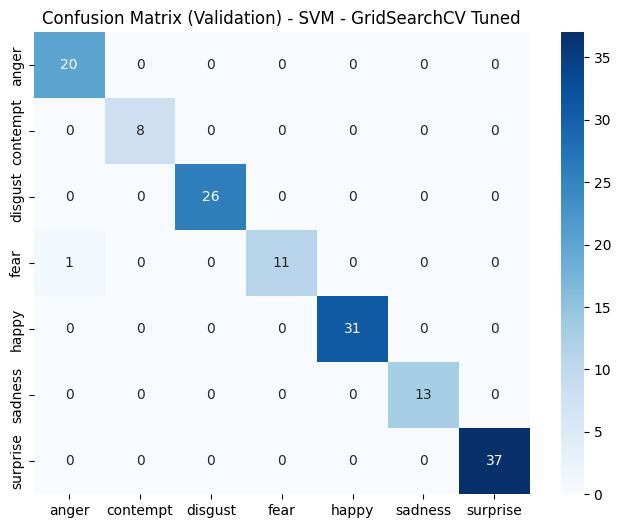


--- Test Set Evaluation: SVM - GridSearchCV Tuned ---
F1: 0.9897
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00        21
    contempt       0.89      1.00      0.94         8
     disgust       1.00      1.00      1.00        27
        fear       1.00      1.00      1.00        11
       happy       1.00      1.00      1.00        31
     sadness       1.00      1.00      1.00        12
    surprise       1.00      0.97      0.99        38

    accuracy                           0.99       148
   macro avg       0.98      1.00      0.99       148
weighted avg       0.99      0.99      0.99       148



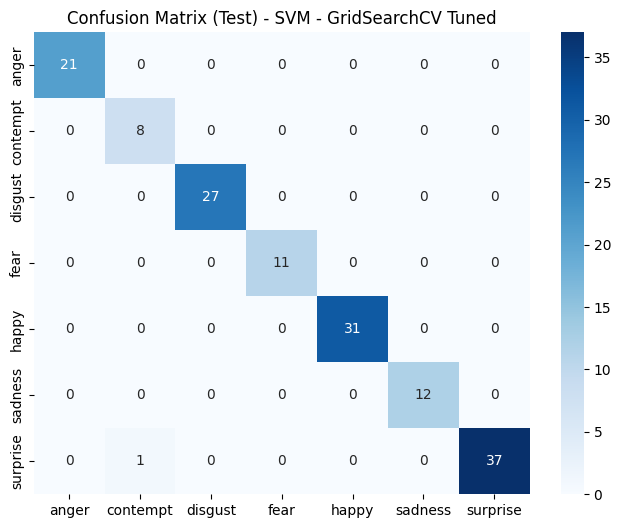

(1.0, 0.9903044993182851, 0.9896918767507003)

In [ ]:
# === GridSearchCV for SVM ===
# Define parameter grid
param_grid = [
    {
        'kernel': ['poly'],
        'C': [50, 100, 200, 500],
        'degree': [2, 3],
        'gamma': ['scale', 0.0001, 0.001, 0.01],
        'coef0': [0, 0.1, 0.5, 1]
    },
    {
        'kernel': ['rbf'],
        'C': [10, 50, 100, 200],
        'gamma': ['scale', 0.0001, 0.001, 0.01]
    }
]


# Define SVC with balanced class weight
svc = SVC(class_weight='balanced', random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# GridSearchCV (note: we use all CPU cores with n_jobs=-1)
svm_grid = GridSearchCV(
    svc,
    param_grid,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2,
    refit=True
)
svm_grid.fit(X_train_all, y_train_smote)
print('Best SVM params:', svm_grid.best_params_)
full_evaluation(svm_grid.best_estimator_, X_train_all, y_train_smote, X_val_all, y_val, X_test_all, y_test, "SVM - GridSearchCV Tuned")

Multilayer Perceptron

[I 2025-05-11 05:31:52,715] A new study created in memory with name: no-name-9de80b91-2ca9-4663-b85a-e865cb99da3e
[I 2025-05-11 05:32:02,693] Trial 0 finished with value: 0.05442178249359131 and parameters: {'hidden_dim': 43, 'dropout_p': 0.31470799853759174, 'lr': 0.0018698591749059512, 'weight_decay': 0.001407963633205585, 'batch_size': 16}. Best is trial 0 with value: 0.05442178249359131.


Epoch 100: Validation Acc: 0.9456


[I 2025-05-11 05:32:05,952] Trial 1 finished with value: 0.1836734414100647 and parameters: {'hidden_dim': 16, 'dropout_p': 0.32627440436923955, 'lr': 0.00016487115661178395, 'weight_decay': 0.011839971668287205, 'batch_size': 64}. Best is trial 0 with value: 0.05442178249359131.


Epoch 100: Validation Acc: 0.8163


[I 2025-05-11 05:32:09,473] Trial 2 finished with value: 0.12925171852111816 and parameters: {'hidden_dim': 25, 'dropout_p': 0.38000557650462563, 'lr': 0.0036031510282195016, 'weight_decay': 0.020857735707044755, 'batch_size': 64}. Best is trial 0 with value: 0.05442178249359131.


...

Epoch 100: Validation Acc: 0.9184


[I 2025-05-11 05:33:54,183] Trial 18 finished with value: 0.020408153533935547 and parameters: {'hidden_dim': 58, 'dropout_p': 0.39677326056716933, 'lr': 0.00871302768006031, 'weight_decay': 0.00020299576768290938, 'batch_size': 16}. Best is trial 18 with value: 0.020408153533935547.


Epoch 100: Validation Acc: 0.9796


[I 2025-05-11 05:34:03,208] Trial 19 finished with value: 0.05442178249359131 and parameters: {'hidden_dim': 59, 'dropout_p': 0.42930091371237283, 'lr': 0.0006573667705097006, 'weight_decay': 0.0004433660007964036, 'batch_size': 16}. Best is trial 18 with value: 0.020408153533935547.


Epoch 100: Validation Acc: 0.9456
Best trial: {'hidden_dim': 58, 'dropout_p': 0.39677326056716933, 'lr': 0.00871302768006031, 'weight_decay': 0.00020299576768290938, 'batch_size': 16}
Epoch 100: Validation Acc: 0.9524
Epoch 200: Validation Acc: 0.9660
Epoch 300: Validation Acc: 0.9796
Epoch 400: Validation Acc: 0.9796
Epoch 500: Validation Acc: 0.9728
Epoch 600: Validation Acc: 0.9524
Epoch 700: Validation Acc: 0.9796
Epoch 800: Validation Acc: 0.9796
Epoch 900: Validation Acc: 0.9728
Epoch 1000: Validation Acc: 0.9660

--- MLP Optuna Tuned (Train) ---
F1 Score: 1.0000
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00       174
    contempt       1.00      1.00      1.00       174
     disgust       1.00      1.00      1.00       174
        fear       1.00      1.00      1.00       174
       happy       1.00      1.00      1.00       174
     sadness       1.00      1.00      1.00       174
    surprise       1.00      1.00      1.00  

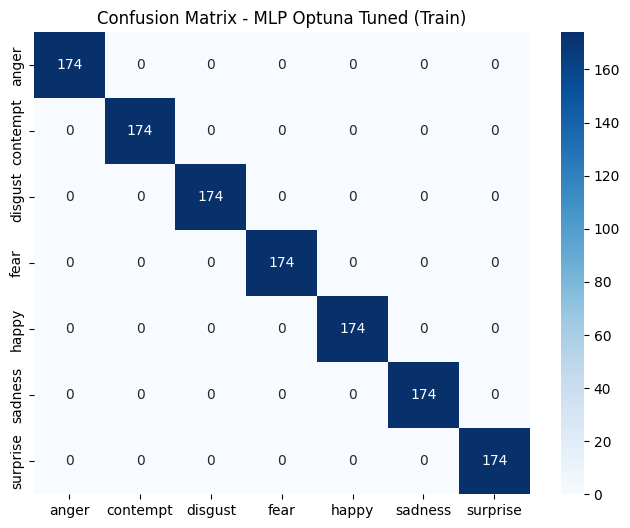


--- MLP Optuna Tuned (Validation) ---
F1 Score: 0.9496
              precision    recall  f1-score   support

       anger       0.95      1.00      0.98        20
    contempt       0.89      1.00      0.94         8
     disgust       0.96      1.00      0.98        26
        fear       1.00      0.83      0.91        12
       happy       0.97      1.00      0.98        31
     sadness       1.00      0.77      0.87        13
    surprise       0.97      1.00      0.99        37

    accuracy                           0.97       147
   macro avg       0.96      0.94      0.95       147
weighted avg       0.97      0.97      0.96       147



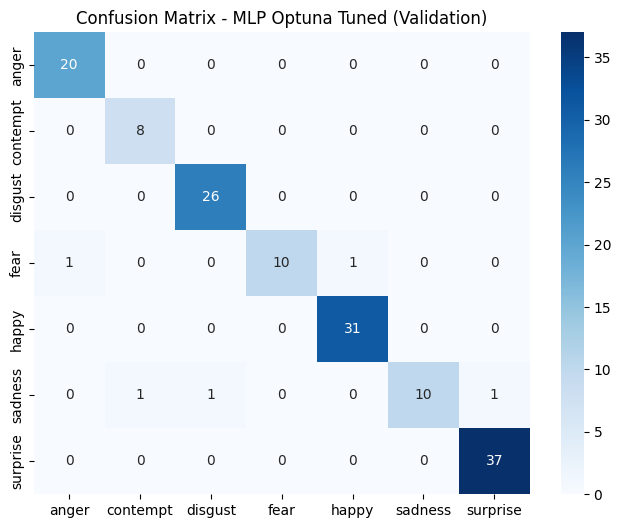


--- MLP Optuna Tuned (Test) ---
F1 Score: 0.9626
              precision    recall  f1-score   support

       anger       1.00      0.95      0.98        21
    contempt       0.89      1.00      0.94         8
     disgust       0.96      1.00      0.98        27
        fear       1.00      0.91      0.95        11
       happy       0.97      1.00      0.98        31
     sadness       0.92      0.92      0.92        12
    surprise       1.00      0.97      0.99        38

    accuracy                           0.97       148
   macro avg       0.96      0.96      0.96       148
weighted avg       0.97      0.97      0.97       148



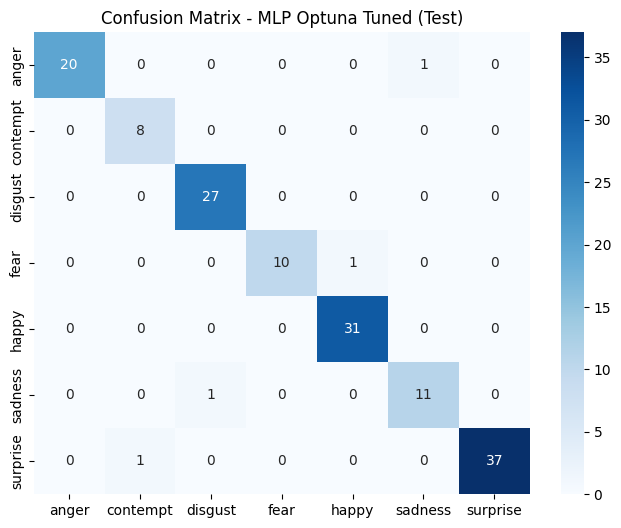

In [ ]:
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=20)
print('Best trial:', study.best_trial.params)

best_params = study.best_trial.params
mlp_optuna = train_mlp(
    X_train_all, y_train_smote, X_val_all, y_val,
    input_dim=X_train_all.shape[1],
    num_classes=len(label_encoder.classes_),
    hidden_dim=best_params['hidden_dim'],
    dropout_p=best_params['dropout_p'],
    lr=best_params['lr'],
    weight_decay=best_params['weight_decay'],
    batch_size=best_params['batch_size'],
    epochs=1000
)
evaluate_mlp(mlp_optuna, X_train_all, y_train_smote, "MLP Optuna Tuned (Train)")
evaluate_mlp(mlp_optuna, X_val_all, y_val, "MLP Optuna Tuned (Validation)")
evaluate_mlp(mlp_optuna, X_test_all, y_test, "MLP Optuna Tuned (Test)")

# Data Visualization

In [ ]:
emotion_colors = {
    'anger': 'red',
    'disgust': 'green',
    'fear': 'purple',
    'happy': 'yellow',
    'contempt': 'gray',
    'sadness': 'blue',
    'surprise': 'pink'
}

Bar Chart for Raw Dataset

<ipython-input-78-51c4933fa6a2>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='emotion', data=full_df, palette=[emotion_colors[emotion] for emotion in full_df['emotion'].unique()])


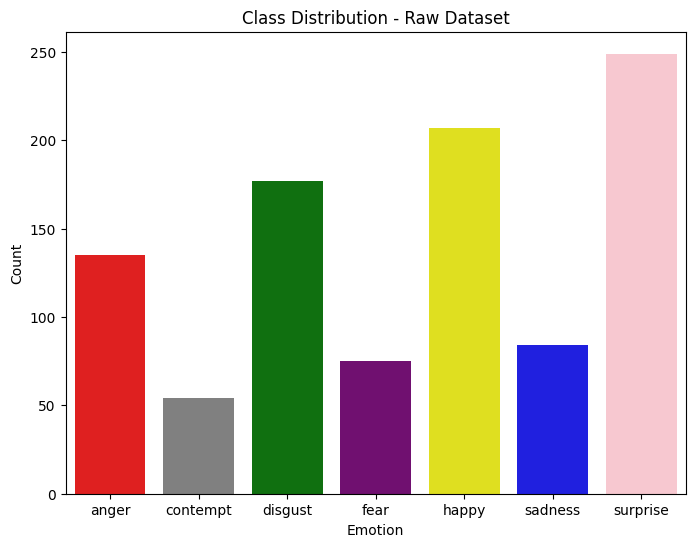

In [ ]:
# Plot class distribution
plt.figure(figsize=(8,6))
sns.countplot(x='emotion', data=full_df, palette=[emotion_colors[emotion] for emotion in full_df['emotion'].unique()])
plt.title('Class Distribution - Raw Dataset')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.show()

Bar Chart for SMOTE Resampled Training Data

<ipython-input-79-53acbe8089b7>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_encoder.classes_, y=np.bincount(y_train_smote), palette=[emotion_colors[emotion] for emotion in label_encoder.classes_])


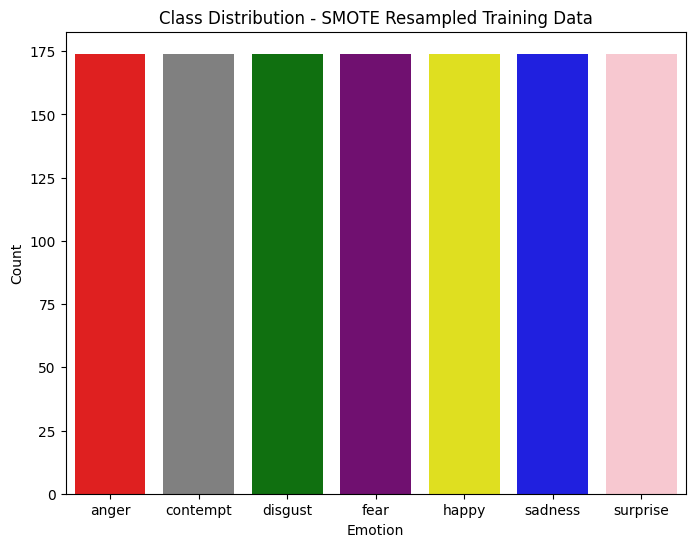

In [ ]:
# Plot SMOTE-resampled class distribution
plt.figure(figsize=(8,6))
sns.barplot(x=label_encoder.classes_, y=np.bincount(y_train_smote), palette=[emotion_colors[emotion] for emotion in label_encoder.classes_])
plt.title('Class Distribution - SMOTE Resampled Training Data')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.show()

Heatmap of Feature Correlations

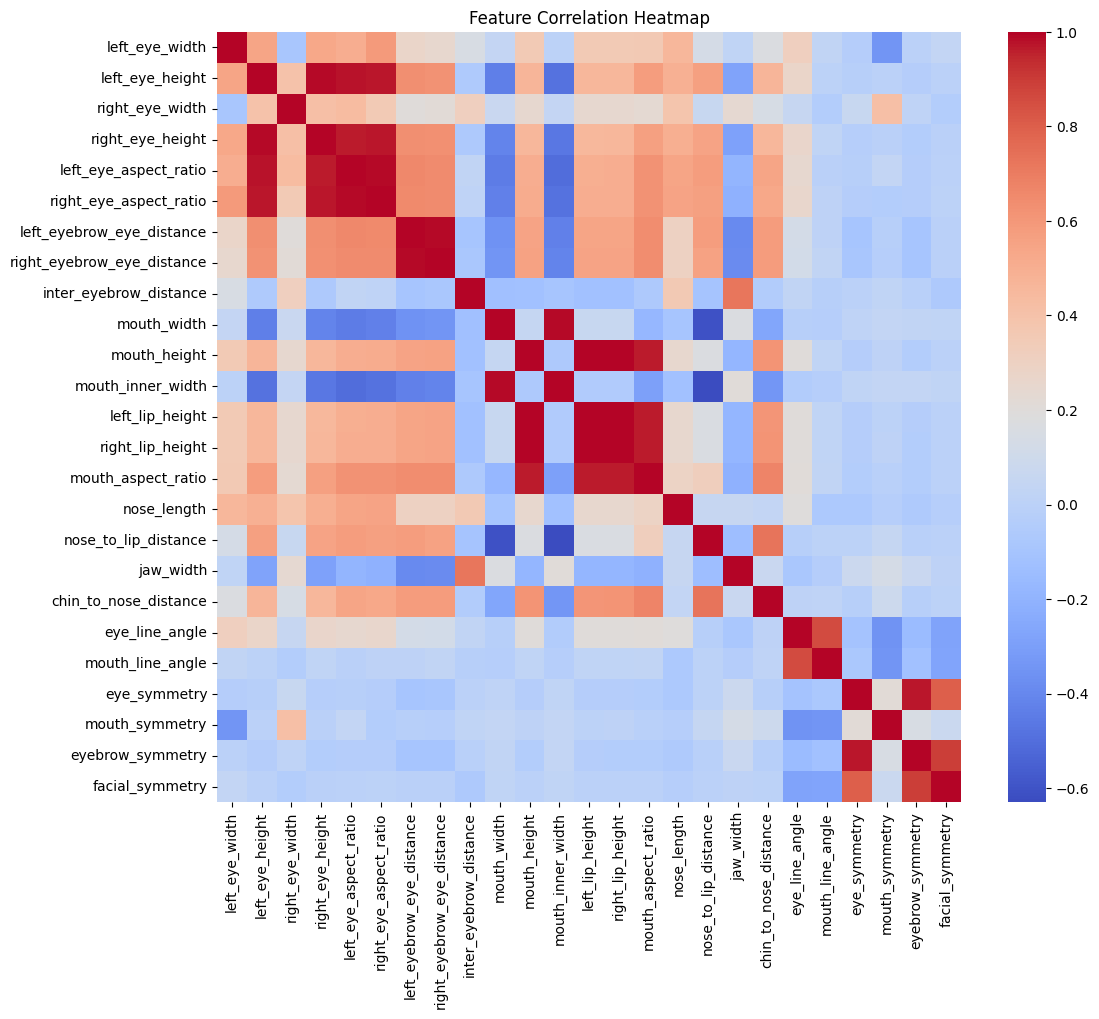

In [ ]:
# Correlation heatmap
plt.figure(figsize=(12,10))
corr_matrix = X_train_raw.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title('Feature Correlation Heatmap')
plt.show()

Bar Chart Comparing All Experiment Results (Train/Val/Test)

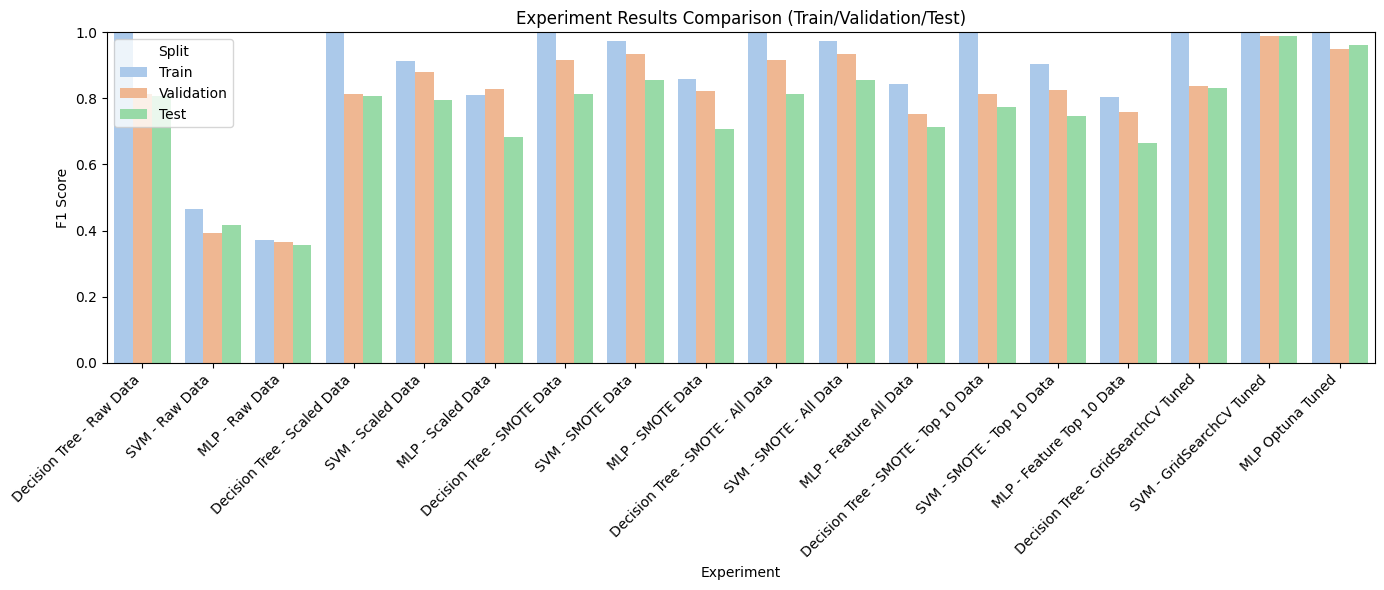

In [ ]:
records = []
for exp_name, results in experiment_results.items():
    for split, f1 in results.items():
        if split in ['Train', 'Validation', 'Test']:
            if 'Decision Tree' in exp_name:
                model = 'Decision Tree'
            elif 'SVM' in exp_name:
                model = 'SVM'
            elif 'MLP' in exp_name:
                model = 'MLP'
            else:
                model = 'Unknown'

            records.append({
                'Model': model,
                'Experiment': exp_name,
                'Split': split,
                'F1 Score': f1
            })

df_results = pd.DataFrame(records)

plt.figure(figsize=(14,6))
sns.barplot(data=df_results, x='Experiment', y='F1 Score', hue='Split', palette='pastel')
plt.title('Experiment Results Comparison (Train/Validation/Test)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


Bar Chart Comparing Only Test Data Across All Experiments

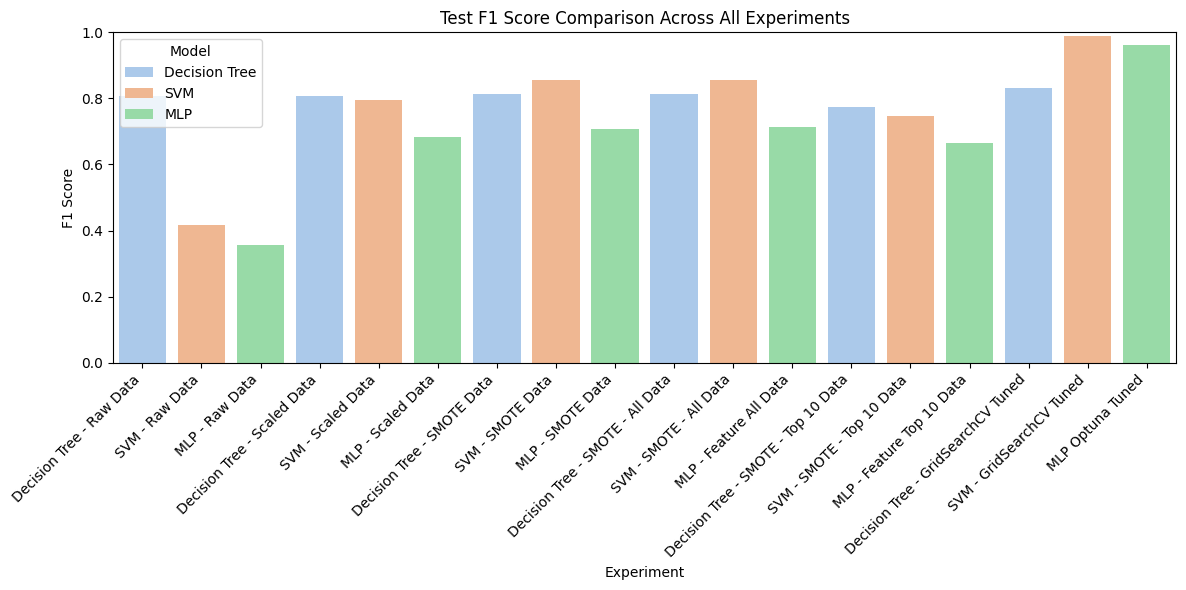

In [ ]:
df_test_only = df_results[df_results['Split'] == 'Test']

plt.figure(figsize=(12,6))
sns.barplot(data=df_test_only, x='Experiment', y='F1 Score', hue='Model', palette='pastel')
plt.title('Test F1 Score Comparison Across All Experiments')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


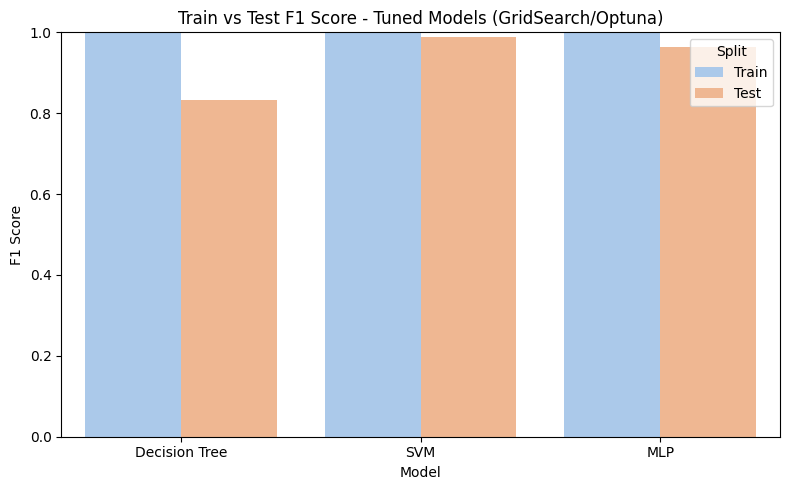

In [ ]:
# Filter tuned models
tuned_keywords = [
    "Decision Tree - GridSearchCV Tuned",
    "SVM - GridSearchCV Tuned",
    "MLP Optuna Tuned"
]

# Build DataFrame from filtered results
records = []
for exp_name in tuned_keywords:
    if exp_name not in experiment_results:
        continue
    for split in ['Train', 'Test']:
        f1 = experiment_results[exp_name].get(split)
        if f1 is not None:
            if 'Decision Tree' in exp_name:
                model = 'Decision Tree'
            elif 'SVM' in exp_name:
                model = 'SVM'
            elif 'MLP' in exp_name:
                model = 'MLP'
            else:
                model = 'Unknown'

            records.append({
                'Model': model,
                'Split': split,
                'F1 Score': f1
            })

df_tuned = pd.DataFrame(records)

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=df_tuned, x='Model', y='F1 Score', hue='Split', palette='pastel')
plt.title('Train vs Test F1 Score - Tuned Models (GridSearch/Optuna)')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Bar Chart per Experiment (Train/Val/Test)

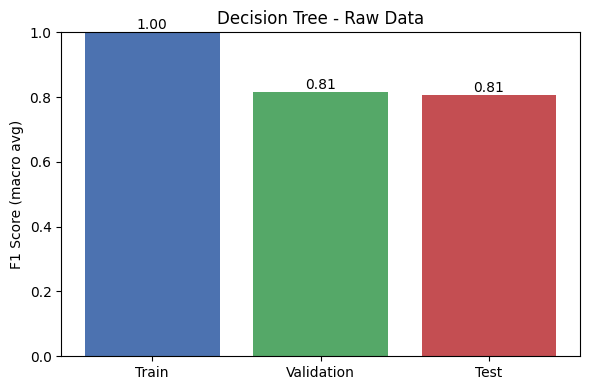

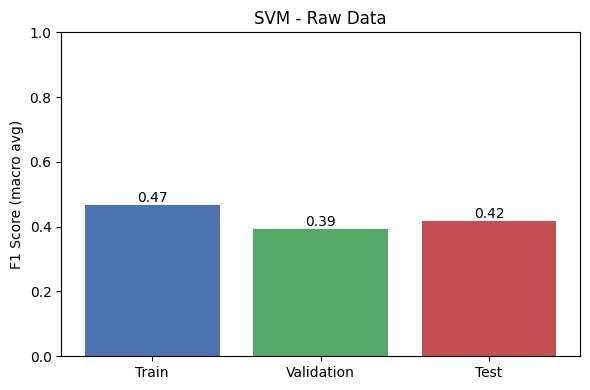

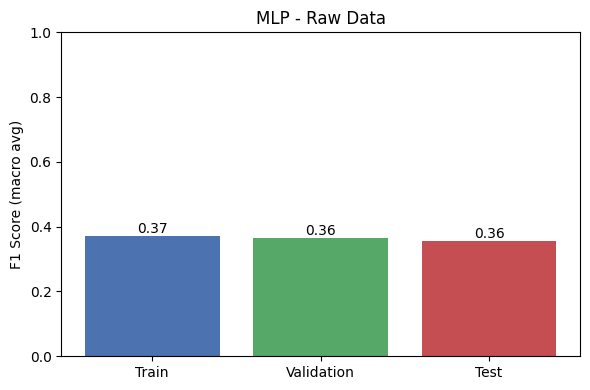

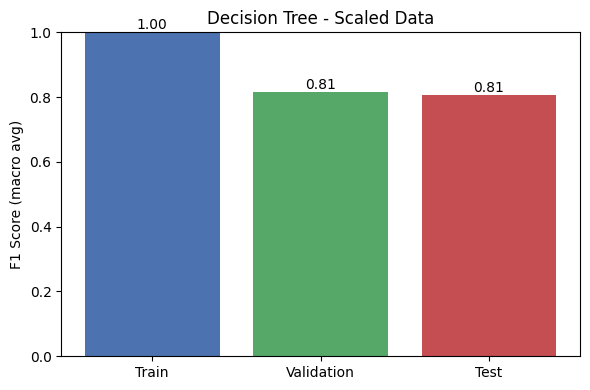

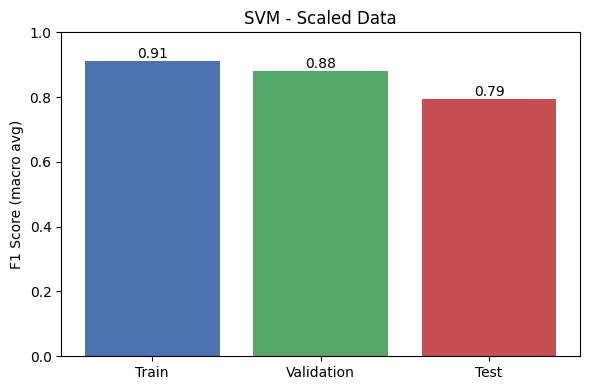

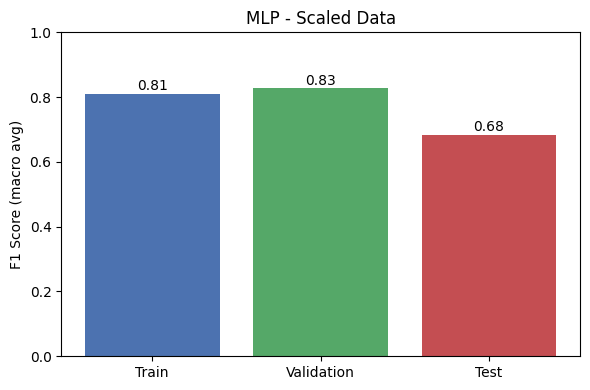

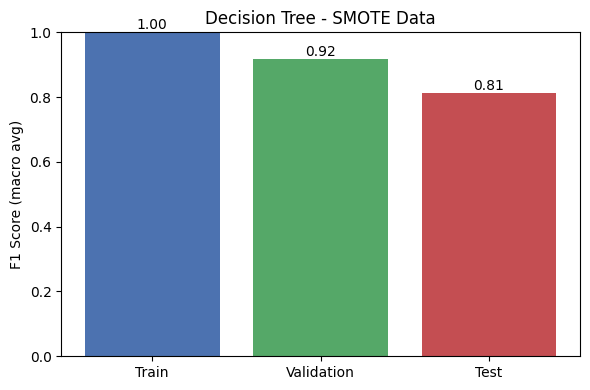

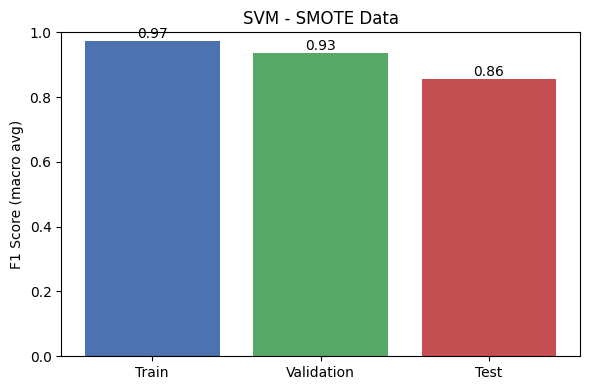

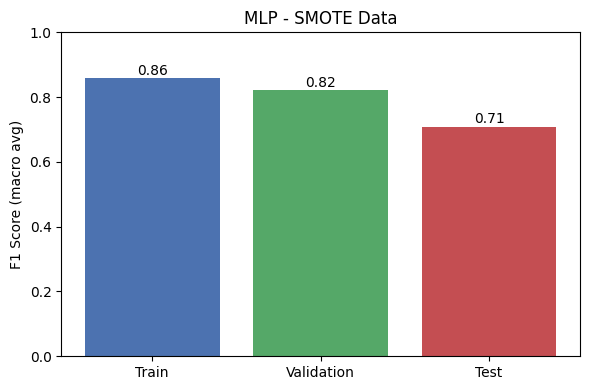

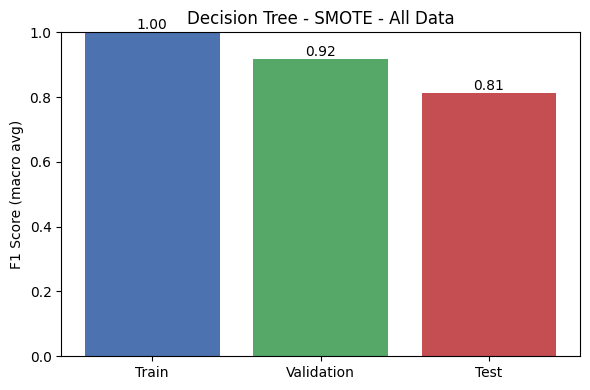

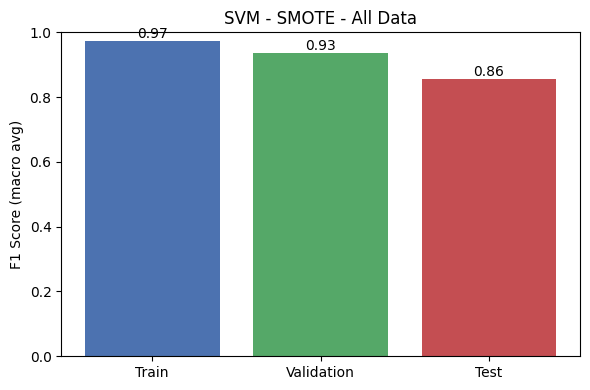

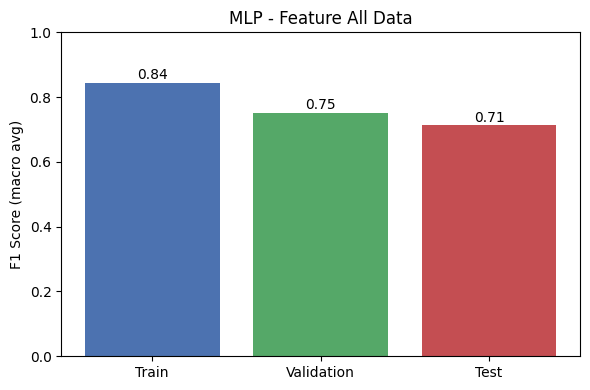

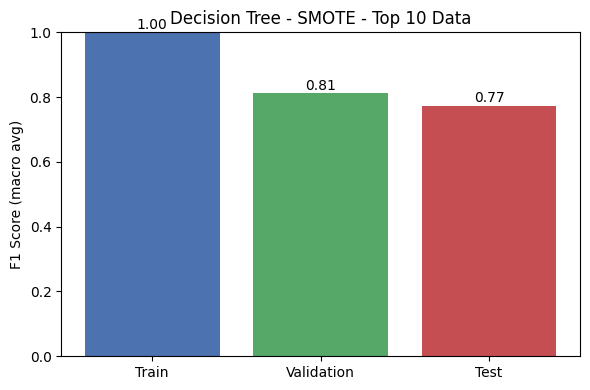

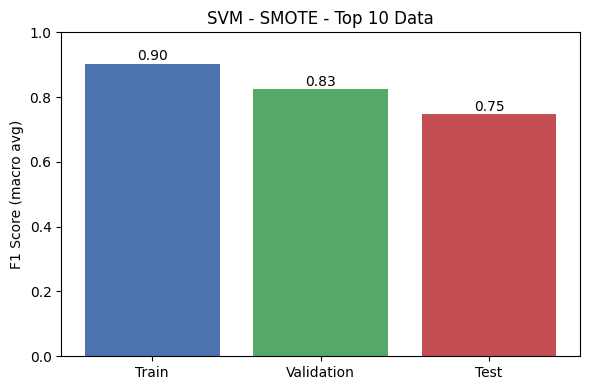

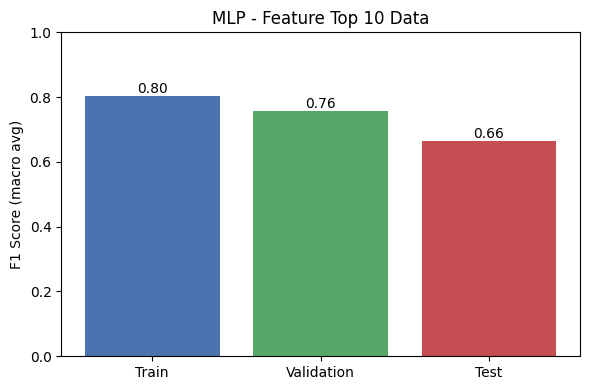

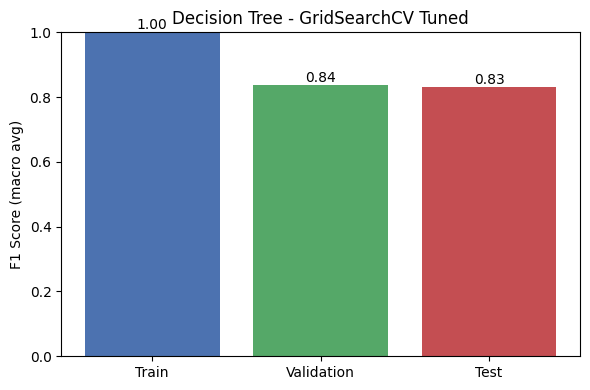

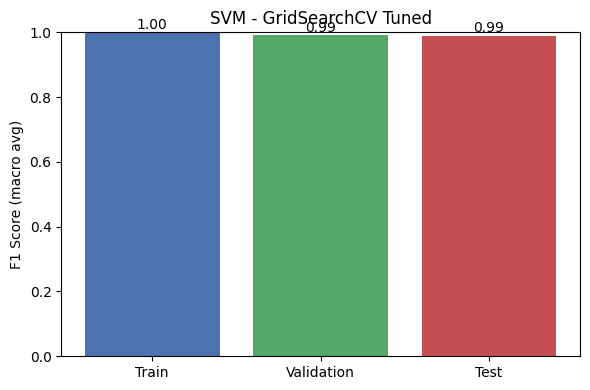

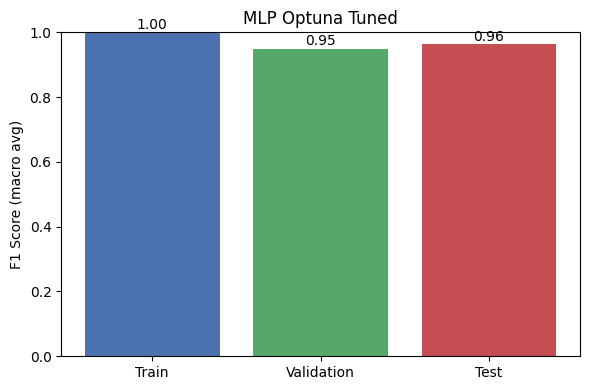

In [ ]:
for experiment_name, results in experiment_results.items():
    if not all(k in results for k in ['Train', 'Validation', 'Test']):
        continue

    plt.figure(figsize=(6, 4))
    splits = ['Train', 'Validation', 'Test']
    f1_scores = [results[split] for split in splits]

    plt.bar(splits, f1_scores, color=['#4c72b0', '#55a868', '#c44e52'])
    plt.ylim(0, 1)
    plt.title(f"{experiment_name}")
    plt.ylabel("F1 Score (macro avg)")
    for i, f1 in enumerate(f1_scores):
        plt.text(i, f1 + 0.01, f"{f1:.2f}", ha='center')
    plt.tight_layout()
    plt.show()